In [0]:
%pip install gradio==4.44.1
dbutils.library.restartPython()

In [0]:
#Imports and project configuration
import os, time, uuid
from datetime import datetime


import gradio as gr
import html
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import functions as F
from pyspark.ml import PipelineModel
from pyspark.ml.classification import MultilayerPerceptronClassificationModel
from pyspark.ml.linalg import VectorUDT

try:
    from pyspark.ml.functions import vector_to_array
except Exception:
    vector_to_array = None

if "SEED" not in globals():
    SEED = 42

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import gradio as gr

from pyspark.sql import functions as F
from pyspark.storagelevel import StorageLevel
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import MultilayerPerceptronClassifier, MultilayerPerceptronClassificationModel
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.linalg import VectorUDT

try:
    from pyspark.ml.functions import vector_to_array
except Exception:
    vector_to_array = None

SEED = 42
CATALOG = "new"
SCHEMA = "airgreenops"
VOLUME = "project_data"
ROOT = f"/Volumes/{CATALOG}/{SCHEMA}/{VOLUME}/airgreenops"

MODEL_ROOT = f"{ROOT}/models/mlp_high_emission"
DELAY_MODEL_ROOT = f"{ROOT}/models/mlp_delay_risk"
XAI_ROOT = f"{ROOT}/xai"

GOLD_TABLE = f"`{CATALOG}`.`{SCHEMA}`.`gold_flight_emissions_clean`"
MLP_SAMPLE_TABLE = f"`{CATALOG}`.`{SCHEMA}`.`mlp_high_emission_sample`"
MLP_SPLIT_TABLE = f"`{CATALOG}`.`{SCHEMA}`.`mlp_high_emission_splits`"
MLP_PREPARED_TABLE = f"`{CATALOG}`.`{SCHEMA}`.`mlp_high_emission_prepared`"
MLP_RESULTS_TABLE = f"`{CATALOG}`.`{SCHEMA}`.`mlp_high_emission_results`"
EXISTING_STRESS_TABLE = f"`{CATALOG}`.`{SCHEMA}`.`mlp_performance_benchmarks`"

PIPELINE_PATH = f"{MODEL_ROOT}/feature_pipeline"
PHASE_C_BENCHMARK_TABLE = f"`{CATALOG}`.`{SCHEMA}`.`phase_c_scalability_benchmarks`"
XAI_GLOBAL_TABLE = f"`{CATALOG}`.`{SCHEMA}`.`phase_c_xai_global_feature_importance`"
XAI_LOCAL_TABLE = f"`{CATALOG}`.`{SCHEMA}`.`phase_c_xai_local_explanations`"

DELAY_SAMPLE_TABLE = f"`{CATALOG}`.`{SCHEMA}`.`mlp_delay_risk_sample`"
DELAY_SPLIT_TABLE = f"`{CATALOG}`.`{SCHEMA}`.`mlp_delay_risk_splits`"
DELAY_PREPARED_TABLE = f"`{CATALOG}`.`{SCHEMA}`.`mlp_delay_risk_prepared`"
DELAY_RESULTS_TABLE = f"`{CATALOG}`.`{SCHEMA}`.`mlp_delay_risk_results`"
DELAY_PIPELINE_PATH = f"{DELAY_MODEL_ROOT}/feature_pipeline"
DELAY_MODEL_PATH = f"{DELAY_MODEL_ROOT}/delay_risk_mlp"

for p in [ROOT, MODEL_ROOT, DELAY_MODEL_ROOT, XAI_ROOT]:
    dbutils.fs.mkdirs(p)

spark.sql(f"USE CATALOG `{CATALOG}`")
spark.sql(f"USE SCHEMA `{SCHEMA}`")
print("Setup complete.")

Setup complete.


In [0]:
#Link checks
required_tables = {
    "Notebook 01 Gold ML table": GOLD_TABLE,
    "Notebook 02 MLP sample": MLP_SAMPLE_TABLE,
    "Notebook 02 MLP splits": MLP_SPLIT_TABLE,
    "Notebook 02 prepared features": MLP_PREPARED_TABLE,
    "Notebook 02 MLP metrics": MLP_RESULTS_TABLE,
}

for label, table_name in required_tables.items():
    n = spark.table(table_name).count()
    print(f"OK - {label}: {table_name} -> {n:,} rows")

for label, path in {
    "Feature pipeline": PIPELINE_PATH,
    "Baseline MLP": f"{MODEL_ROOT}/baseline_mlp",
    "Deep MLP": f"{MODEL_ROOT}/deep_mlp",
    "Wide MLP": f"{MODEL_ROOT}/wide_mlp",
}.items():
    files = dbutils.fs.ls(path)
    print(f"OK - {label}: {path} -> {len(files)} files/folders")

best_row = (
    spark.table(MLP_RESULTS_TABLE)
    .orderBy(F.desc("validation_f1_high_emission"), F.desc("validation_auc"))
    .first()
)
BEST_MODEL_NAME = best_row["model_name"]
BEST_MODEL_PATH = best_row["model_path"]
INPUT_SIZE = len(spark.table(MLP_PREPARED_TABLE).select("features").first()[0])

print("Best high-emission model:", BEST_MODEL_NAME)
print("Best model path:", BEST_MODEL_PATH)
print("Input feature vector size:", INPUT_SIZE)

OK - Notebook 01 Gold ML table: `new`.`airgreenops`.`gold_flight_emissions_clean` -> 20,588,136 rows
OK - Notebook 02 MLP sample: `new`.`airgreenops`.`mlp_high_emission_sample` -> 999,391 rows
OK - Notebook 02 MLP splits: `new`.`airgreenops`.`mlp_high_emission_splits` -> 819,917 rows
OK - Notebook 02 prepared features: `new`.`airgreenops`.`mlp_high_emission_prepared` -> 819,917 rows
OK - Notebook 02 MLP metrics: `new`.`airgreenops`.`mlp_high_emission_results` -> 3 rows
OK - Feature pipeline: /Volumes/new/airgreenops/project_data/airgreenops/models/mlp_high_emission/feature_pipeline -> 2 files/folders
OK - Baseline MLP: /Volumes/new/airgreenops/project_data/airgreenops/models/mlp_high_emission/baseline_mlp -> 2 files/folders
OK - Deep MLP: /Volumes/new/airgreenops/project_data/airgreenops/models/mlp_high_emission/deep_mlp -> 2 files/folders
OK - Wide MLP: /Volumes/new/airgreenops/project_data/airgreenops/models/mlp_high_emission/wide_mlp -> 2 files/folders
Best high-emission model: deep

In [0]:
#Scalability benchmark: 20% vs 100%, and shuffle partitions 4/8/16
BENCHMARK_RUN_ID = str(uuid.uuid4())

def safe_spark_conf(key, default="not_available"):
    try:
        return spark.conf.get(key)
    except Exception:
        return default

def run_phase_c_benchmark(data_fraction, shuffle_partitions, max_iter=20):
    spark.conf.set("spark.sql.shuffle.partitions", str(shuffle_partitions))
    base_df = spark.table(MLP_PREPARED_TABLE).where(F.col("set") == "train").select("label", "features")
    bench_df = base_df.sample(False, data_fraction, seed=SEED) if data_fraction < 1.0 else base_df
    bench_df = bench_df.repartition(shuffle_partitions).persist(StorageLevel.MEMORY_AND_DISK)

    total_start = time.time()
    cache_start = time.time()
    rows = bench_df.count()
    cache_seconds = time.time() - cache_start

    mlp = MultilayerPerceptronClassifier(
        labelCol="label",
        featuresCol="features",
        predictionCol="prediction",
        layers=[INPUT_SIZE, 32, 2],
        maxIter=max_iter,
        blockSize=128,
        seed=SEED
    )
    fit_start = time.time()
    _ = mlp.fit(bench_df)
    fit_seconds = time.time() - fit_start
    total_seconds = time.time() - total_start
    bench_df.unpersist()

    return {
        "benchmark_run_id": BENCHMARK_RUN_ID,
        "timestamp": datetime.now().isoformat(),
        "model_family": "MLP high avoidable emissions",
        "data_fraction": float(data_fraction),
        "data_scale_percent": int(data_fraction * 100),
        "shuffle_partitions": int(shuffle_partitions),
        "rows": int(rows),
        "cache_latency_seconds": float(cache_seconds),
        "fit_latency_seconds": float(fit_seconds),
        "total_latency_seconds": float(total_seconds),
        "spark_app_id": spark.sparkContext.applicationId,
        "spark_master": spark.sparkContext.master,
        "spark_sql_shuffle_partitions": safe_spark_conf("spark.sql.shuffle.partitions"),
        "databricks_cluster_id": safe_spark_conf("spark.databricks.clusterUsageTags.clusterId"),
        "databricks_cluster_name": safe_spark_conf("spark.databricks.clusterUsageTags.clusterName"),
        "databricks_num_workers": safe_spark_conf("spark.databricks.clusterUsageTags.clusterWorkers")
    }

rows = []
for frac in [0.20, 1.00]:
    for partitions in [4, 8, 16]:
        print(f"Benchmark: {int(frac*100)}% data, {partitions} shuffle partitions")
        rows.append(run_phase_c_benchmark(frac, partitions, max_iter=20))

phase_c_pdf = pd.DataFrame(rows)
spark.createDataFrame(phase_c_pdf).write.format("delta").mode("append").option("mergeSchema", "true").saveAsTable(PHASE_C_BENCHMARK_TABLE)
print("Saved:", PHASE_C_BENCHMARK_TABLE)
display(phase_c_pdf)

Benchmark: 20% data, 4 shuffle partitions
Benchmark: 20% data, 8 shuffle partitions
Benchmark: 20% data, 16 shuffle partitions
Benchmark: 100% data, 4 shuffle partitions
Benchmark: 100% data, 8 shuffle partitions
Benchmark: 100% data, 16 shuffle partitions
Saved: `new`.`airgreenops`.`phase_c_scalability_benchmarks`


benchmark_run_id,timestamp,model_family,data_fraction,data_scale_percent,shuffle_partitions,rows,cache_latency_seconds,fit_latency_seconds,total_latency_seconds,spark_app_id,spark_master,spark_sql_shuffle_partitions,databricks_cluster_id,databricks_cluster_name,databricks_num_workers
ab97f3e8-ed46-40e9-ad12-492263349475,2026-05-21T06:42:59.652739,MLP high avoidable emissions,0.2,20,4,104302,3.2626001834869385,38.82187294960022,42.248512744903564,app-20260521062714-0000,spark://10.204.162.49:7077,4,0520-213232-ffphhy4w,mlp-classic (clone),7
ab97f3e8-ed46-40e9-ad12-492263349475,2026-05-21T06:43:17.167212,MLP high avoidable emissions,0.2,20,8,104302,1.6625988483428955,15.394681453704834,17.10171341896057,app-20260521062714-0000,spark://10.204.162.49:7077,8,0520-213232-ffphhy4w,mlp-classic (clone),7
ab97f3e8-ed46-40e9-ad12-492263349475,2026-05-21T06:43:29.332563,MLP high avoidable emissions,0.2,20,16,104302,1.2676582336425781,10.449339151382446,11.745599508285522,app-20260521062714-0000,spark://10.204.162.49:7077,16,0520-213232-ffphhy4w,mlp-classic (clone),7
ab97f3e8-ed46-40e9-ad12-492263349475,2026-05-21T06:43:57.534850,MLP high avoidable emissions,1.0,100,4,520608,2.311767101287842,25.480202674865723,27.819937705993652,app-20260521062714-0000,spark://10.204.162.49:7077,4,0520-213232-ffphhy4w,mlp-classic (clone),7
ab97f3e8-ed46-40e9-ad12-492263349475,2026-05-21T06:44:18.474096,MLP high avoidable emissions,1.0,100,8,520608,3.1165771484375,17.368903398513794,20.511300086975098,app-20260521062714-0000,spark://10.204.162.49:7077,8,0520-213232-ffphhy4w,mlp-classic (clone),7
ab97f3e8-ed46-40e9-ad12-492263349475,2026-05-21T06:44:35.750912,MLP high avoidable emissions,1.0,100,16,520608,1.8033227920532227,15.025376796722412,16.852320909500122,app-20260521062714-0000,spark://10.204.162.49:7077,16,0520-213232-ffphhy4w,mlp-classic (clone),7


benchmark_run_id,timestamp,model_family,data_fraction,data_scale_percent,shuffle_partitions,rows,cache_latency_seconds,fit_latency_seconds,total_latency_seconds,spark_app_id,spark_master,spark_sql_shuffle_partitions,databricks_cluster_id,databricks_cluster_name,databricks_num_workers
ab97f3e8-ed46-40e9-ad12-492263349475,2026-05-21T06:42:59.652739,MLP high avoidable emissions,0.2,20,4,104302,3.2626001834869385,38.82187294960022,42.248512744903564,app-20260521062714-0000,spark://10.204.162.49:7077,4,0520-213232-ffphhy4w,mlp-classic (clone),7
ab97f3e8-ed46-40e9-ad12-492263349475,2026-05-21T06:43:17.167212,MLP high avoidable emissions,0.2,20,8,104302,1.6625988483428955,15.394681453704834,17.10171341896057,app-20260521062714-0000,spark://10.204.162.49:7077,8,0520-213232-ffphhy4w,mlp-classic (clone),7
ab97f3e8-ed46-40e9-ad12-492263349475,2026-05-21T06:43:29.332563,MLP high avoidable emissions,0.2,20,16,104302,1.2676582336425781,10.449339151382446,11.745599508285522,app-20260521062714-0000,spark://10.204.162.49:7077,16,0520-213232-ffphhy4w,mlp-classic (clone),7
ab97f3e8-ed46-40e9-ad12-492263349475,2026-05-21T06:43:57.534850,MLP high avoidable emissions,1.0,100,4,520608,2.311767101287842,25.480202674865723,27.819937705993652,app-20260521062714-0000,spark://10.204.162.49:7077,4,0520-213232-ffphhy4w,mlp-classic (clone),7
ab97f3e8-ed46-40e9-ad12-492263349475,2026-05-21T06:44:18.474096,MLP high avoidable emissions,1.0,100,8,520608,3.1165771484375,17.368903398513794,20.511300086975098,app-20260521062714-0000,spark://10.204.162.49:7077,8,0520-213232-ffphhy4w,mlp-classic (clone),7
ab97f3e8-ed46-40e9-ad12-492263349475,2026-05-21T06:44:35.750912,MLP high avoidable emissions,1.0,100,16,520608,1.8033227920532227,15.025376796722412,16.852320909500122,app-20260521062714-0000,spark://10.204.162.49:7077,16,0520-213232-ffphhy4w,mlp-classic (clone),7


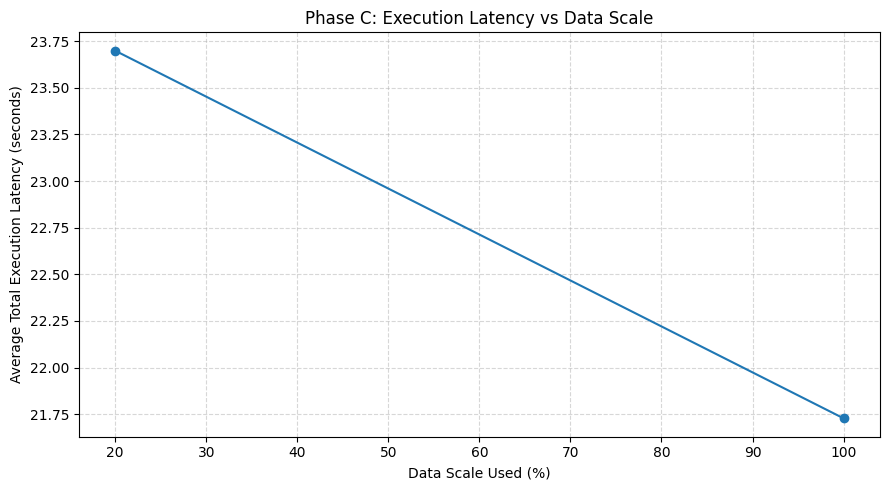

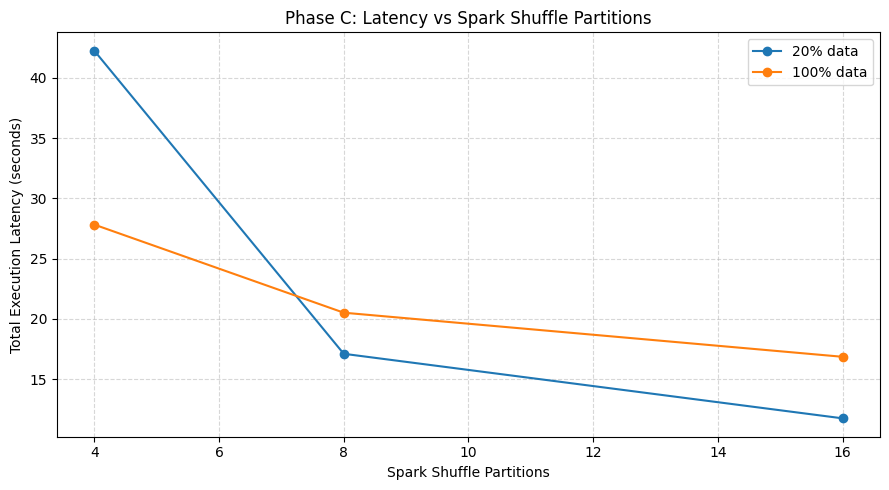

In [0]:
#Benchmark plots
bench_pdf = spark.table(PHASE_C_BENCHMARK_TABLE).where(F.col("benchmark_run_id") == BENCHMARK_RUN_ID).toPandas()
bench_pdf = bench_pdf.sort_values(["data_scale_percent", "shuffle_partitions"])
display(bench_pdf)

scale_summary = bench_pdf.groupby("data_scale_percent", as_index=False)["total_latency_seconds"].mean()
plt.figure(figsize=(9, 5))
plt.plot(scale_summary["data_scale_percent"], scale_summary["total_latency_seconds"], marker="o")
plt.xlabel("Data Scale Used (%)")
plt.ylabel("Average Total Execution Latency (seconds)")
plt.title("Phase C: Execution Latency vs Data Scale")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("/tmp/phase_c_latency_vs_data_scale.png", dpi=200)
plt.show()

plt.figure(figsize=(9, 5))
for frac in sorted(bench_pdf["data_fraction"].unique()):
    subset = bench_pdf[bench_pdf["data_fraction"] == frac].sort_values("shuffle_partitions")
    plt.plot(subset["shuffle_partitions"], subset["total_latency_seconds"], marker="o", label=f"{int(frac*100)}% data")
plt.xlabel("Spark Shuffle Partitions")
plt.ylabel("Total Execution Latency (seconds)")
plt.title("Phase C: Latency vs Spark Shuffle Partitions")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("/tmp/phase_c_latency_vs_shuffle_partitions.png", dpi=200)
plt.show()

In [0]:
# Train Model 2: High operational delay risk

import time
import pandas as pd

from pyspark.sql import functions as F
from pyspark.storagelevel import StorageLevel
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import MultilayerPerceptronClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, BinaryClassificationEvaluator


TARGET2 = "high_delay_risk_flag"
LABEL_COL = "label"
TARGET_SAMPLE_SIZE = 1_000_000
CONGESTION_SCORE_COL = "congestion_score"

categorical_cols = [
    "origin",
    "dest",
    "airline",
    "aircraft_group",
    "season",
    "time_of_day",
    "congestion_level",
    "weather_risk_level"
]

numeric_cols = [
    "month",
    "day_of_week",
    "scheduled_dep_hour",
    "distance",
    "fuel_burn_kg_per_min",
    "airport_hour_departure_count_cleaned",
    CONGESTION_SCORE_COL,
    "wind_speed",
    "precipitation_1hr"
]

feature_cols_raw = categorical_cols + numeric_cols


def congestion_score_expr(col_name="congestion_level"):
    c = F.lower(F.trim(F.coalesce(F.col(col_name).cast("string"), F.lit("unknown"))))

    return (
        F.when(c.isin("very low", "low", "light"), F.lit(0.0))
         .when(c.isin("medium", "moderate", "normal"), F.lit(1.0))
         .when(c.isin("high", "heavy"), F.lit(2.0))
         .when(c.isin("severe", "very high", "extreme"), F.lit(3.0))
         .otherwise(F.lit(1.0))
    )


gold_source = spark.table(GOLD_TABLE)

required_source_cols = list(dict.fromkeys(
    [c for c in feature_cols_raw if c != CONGESTION_SCORE_COL] + ["dep_delay_winsorized"]
))

missing = [c for c in required_source_cols if c not in gold_source.columns]

if missing:
    raise Exception(f"Missing columns for Model 2: {missing}")

gold = (
    gold_source
    .select(*required_source_cols)
    .withColumn(CONGESTION_SCORE_COL, congestion_score_expr("congestion_level"))
)

delay_p75 = (
    gold
    .where(F.col("dep_delay_winsorized").isNotNull())
    .approxQuantile("dep_delay_winsorized", [0.75], 0.01)[0]
)

print("Delay-risk threshold p75:", delay_p75)

base2 = (
    gold
    .select(*(feature_cols_raw + ["dep_delay_winsorized"]))
    .dropna(subset=feature_cols_raw + ["dep_delay_winsorized"])
    .withColumn(
        TARGET2,
        (F.col("dep_delay_winsorized") >= F.lit(delay_p75)).cast("int")
    )
    .withColumn(LABEL_COL, F.col(TARGET2).cast("double"))
    .drop("dep_delay_winsorized", TARGET2)
)

base2_count = base2.count()

if base2_count == 0:
    raise ValueError("Model 2 base dataset has 0 rows after dropna. Check required feature columns.")

fraction = min(1.0, TARGET_SAMPLE_SIZE / base2_count)

sample2 = base2.sample(False, fraction, seed=SEED)

sample2.write.format("delta") \
    .mode("overwrite") \
    .option("overwriteSchema", "true") \
    .saveAsTable(DELAY_SAMPLE_TABLE)

print("Sample label distribution:")
display(
    spark.table(DELAY_SAMPLE_TABLE)
    .groupBy("label")
    .count()
    .orderBy("label")
)

print("Congestion distribution and delay-risk rate:")
display(
    spark.table(DELAY_SAMPLE_TABLE)
    .groupBy("congestion_level")
    .agg(
        F.count("*").alias("rows"),
        F.avg("label").alias("high_delay_rate"),
        F.avg("airport_hour_departure_count_cleaned").alias("avg_departures_this_hour"),
        F.avg("congestion_score").alias("avg_congestion_score")
    )
    .orderBy(F.desc("high_delay_rate"))
)

raw2 = spark.table(DELAY_SAMPLE_TABLE).withColumn("split_rand", F.rand(SEED))

splits2 = (
    raw2.where(F.col("split_rand") < 0.70)
        .withColumn("set", F.lit("train"))
    .unionByName(
        raw2.where((F.col("split_rand") >= 0.70) & (F.col("split_rand") < 0.85))
            .withColumn("set", F.lit("val"))
    )
    .unionByName(
        raw2.where(F.col("split_rand") >= 0.85)
            .withColumn("set", F.lit("test"))
    )
    .drop("split_rand")
)

splits2.write.format("delta") \
    .mode("overwrite") \
    .option("overwriteSchema", "true") \
    .saveAsTable(DELAY_SPLIT_TABLE)

indexers2 = [
    StringIndexer(
        inputCol=c,
        outputCol=f"{c}_idx",
        handleInvalid="keep"
    )
    for c in categorical_cols
]

encoders2 = [
    OneHotEncoder(
        inputCol=f"{c}_idx",
        outputCol=f"{c}_ohe",
        dropLast=False,
        handleInvalid="keep"
    )
    for c in categorical_cols
]

num_assembler2 = VectorAssembler(
    inputCols=numeric_cols,
    outputCol="num_vec",
    handleInvalid="keep"
)

num_scaler2 = StandardScaler(
    inputCol="num_vec",
    outputCol="num_scaled",
    withMean=False,
    withStd=True
)

final_assembler2 = VectorAssembler(
    inputCols=["num_scaled"] + [f"{c}_ohe" for c in categorical_cols],
    outputCol="features",
    handleInvalid="keep"
)

pipe2 = Pipeline(
    stages=indexers2 + encoders2 + [num_assembler2, num_scaler2, final_assembler2]
)

pipe_model2 = pipe2.fit(
    splits2.where(F.col("set") == "train")
)

pipe_model2.write().overwrite().save(DELAY_PIPELINE_PATH)

prepared2 = pipe_model2.transform(splits2)

prepared2.select("set", "label", "features", *feature_cols_raw) \
    .write.format("delta") \
    .mode("overwrite") \
    .option("overwriteSchema", "true") \
    .saveAsTable(DELAY_PREPARED_TABLE)

INPUT2 = len(
    spark.table(DELAY_PREPARED_TABLE)
    .select("features")
    .first()[0]
)

train2 = (
    spark.table(DELAY_PREPARED_TABLE)
    .where(F.col("set") == "train")
    .select("label", "features")
    .persist(StorageLevel.MEMORY_AND_DISK)
)

val2 = (
    spark.table(DELAY_PREPARED_TABLE)
    .where(F.col("set") == "val")
    .select("label", "features")
    .persist(StorageLevel.MEMORY_AND_DISK)
)

model2 = MultilayerPerceptronClassifier(
    labelCol="label",
    featuresCol="features",
    predictionCol="prediction",
    layers=[INPUT2, 64, 32, 2],
    maxIter=60,
    blockSize=128,
    seed=SEED
)

start = time.time()
delay_model = model2.fit(train2)
train_seconds = time.time() - start

delay_model.write().overwrite().save(DELAY_MODEL_PATH)

pred2 = delay_model.transform(val2)

acc2 = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
).evaluate(pred2)

f12 = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1"
).evaluate(pred2)

auc2 = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
).evaluate(pred2)

result2 = pd.DataFrame([{
    "model_name": "delay_risk_mlp",
    "model_path": DELAY_MODEL_PATH,
    "feature_pipeline_path": DELAY_PIPELINE_PATH,
    "target_definition": f"dep_delay_winsorized >= p75 ({delay_p75})",
    "validation_accuracy": float(acc2),
    "validation_f1": float(f12),
    "validation_auc": float(auc2),
    "training_seconds": float(train_seconds),
    "training_rows": int(train2.count()),
    "input_feature_vector_size": int(INPUT2)
}])

spark.createDataFrame(result2) \
    .write.format("delta") \
    .mode("overwrite") \
    .option("overwriteSchema", "true") \
    .saveAsTable(DELAY_RESULTS_TABLE)

train2.unpersist()
val2.unpersist()

print("Saved Model 2:", DELAY_MODEL_PATH)
print("Saved Model 2 feature pipeline:", DELAY_PIPELINE_PATH)

display(result2)

Delay-risk threshold p75: 10.0
Sample label distribution:


label,count
0.0,750266
1.0,248613


Congestion distribution and delay-risk rate:


congestion_level,rows,high_delay_rate,avg_departures_this_hour,avg_congestion_score
high,575325,0.2627645243992526,35.71969234780342,2.0
medium,251582,0.23825631404472497,9.121829065672426,1.0
low,171972,0.21804130905031052,2.3311876351964274,0.0


Saved Model 2: /Volumes/new/airgreenops/project_data/airgreenops/models/mlp_delay_risk/delay_risk_mlp
Saved Model 2 feature pipeline: /Volumes/new/airgreenops/project_data/airgreenops/models/mlp_delay_risk/feature_pipeline


model_name,model_path,feature_pipeline_path,target_definition,validation_accuracy,validation_f1,validation_auc,training_seconds,training_rows,input_feature_vector_size
delay_risk_mlp,/Volumes/new/airgreenops/project_data/airgreenops/models/mlp_delay_risk/delay_risk_mlp,/Volumes/new/airgreenops/project_data/airgreenops/models/mlp_delay_risk/feature_pipeline,dep_delay_winsorized >= p75 (10.0),0.7543144630556353,0.6818083170664955,0.6781364807979277,509.21182441711426,699725,779


In [0]:
# Model evaluation for Model 2: High operational delay risk

import time
import pandas as pd

from pyspark.sql import functions as F
from pyspark.sql.types import ArrayType, DoubleType
from pyspark.ml.classification import MultilayerPerceptronClassificationModel
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

# For extracting class-1 probability from Spark vector columns
try:
    from pyspark.ml.functions import vector_to_array
    HAS_VECTOR_TO_ARRAY = True
except Exception:
    HAS_VECTOR_TO_ARRAY = False
    to_array_udf = F.udf(
        lambda v: v.toArray().tolist() if v is not None else None,
        ArrayType(DoubleType())
    )



EVAL_SET = "test"

HIGH_RISK_LABEL = 1

# Small value used to avoid log(0) when calculating log loss.
EPS = 1e-15


#Output Delta tables
DELAY_FULL_EVAL_TABLE = f"`{CATALOG}`.`{SCHEMA}`.`mlp_delay_risk_full_evaluation`"
DELAY_CONFUSION_TABLE = f"`{CATALOG}`.`{SCHEMA}`.`mlp_delay_risk_confusion_matrix`"



DELAY_TRAINING_OBJECTIVE_LOSS = None


# Load saved model and prepared evaluation data

delay_model = MultilayerPerceptronClassificationModel.load(DELAY_MODEL_PATH)

eval_df = (
    spark.table(DELAY_PREPARED_TABLE)
    .where(F.col("set") == F.lit(EVAL_SET))
    .select(
        F.col("label").cast("double").alias("label"),
        F.col("features")
    )
    .cache()
)

row_count = eval_df.count()

if row_count == 0:
    raise ValueError(f"No rows found for EVAL_SET='{EVAL_SET}' in {DELAY_PREPARED_TABLE}")

distinct_labels = eval_df.select("label").distinct().count()
if distinct_labels < 2:
    raise ValueError(
        f"EVAL_SET='{EVAL_SET}' contains only one class. "
        "AUC and class-specific F1 require both label 0 and label 1."
    )

print(f"Evaluating delay_risk_mlp on {EVAL_SET} set")
print("Rows:", row_count)


#Run prediction

start_time = time.time()

pred = delay_model.transform(eval_df).cache()
pred.count()

inference_seconds = time.time() - start_time


# Extract probability for class 1 and calculate evaluation log-loss

if HAS_VECTOR_TO_ARRAY:
    pred_scored = pred.withColumn(
        "probability_array",
        vector_to_array(F.col("probability"))
    )
else:
    pred_scored = pred.withColumn(
        "probability_array",
        to_array_udf(F.col("probability"))
    )

pred_scored = (
    pred_scored
    .withColumn("p_high_raw", F.col("probability_array")[HIGH_RISK_LABEL])
    .withColumn(
        "p_high",
        F.greatest(
            F.lit(EPS),
            F.least(F.lit(1.0 - EPS), F.col("p_high_raw"))
        )
    )
)

eval_log_loss = pred_scored.select(
    F.avg(
        -(
            F.col("label") * F.log(F.col("p_high")) +
            (F.lit(1.0) - F.col("label")) * F.log(F.lit(1.0) - F.col("p_high"))
        )
    ).alias("eval_log_loss")
).first()["eval_log_loss"]

eval_log_loss = float(eval_log_loss)

if DELAY_TRAINING_OBJECTIVE_LOSS is None:
    reported_loss = eval_log_loss
    loss_definition = "Evaluation binary log-loss calculated from predicted probabilities"
else:
    reported_loss = float(DELAY_TRAINING_OBJECTIVE_LOSS)
    loss_definition = "Training final objective loss pasted from delay model training cell"


# Overall metrics

accuracy = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
).evaluate(pred_scored)

weighted_precision = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="weightedPrecision"
).evaluate(pred_scored)

weighted_recall = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="weightedRecall"
).evaluate(pred_scored)

weighted_f1_spark = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1"
).evaluate(pred_scored)

roc_auc = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
).evaluate(pred_scored)

pr_auc = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderPR"
).evaluate(pred_scored)


# Confusion matrix counts

cm_counts = pred_scored.select(
    F.col("label").cast("int").alias("actual"),
    F.col("prediction").cast("int").alias("predicted")
).agg(
    F.sum(F.when((F.col("actual") == 1) & (F.col("predicted") == 1), 1).otherwise(0)).alias("tp"),
    F.sum(F.when((F.col("actual") == 0) & (F.col("predicted") == 0), 1).otherwise(0)).alias("tn"),
    F.sum(F.when((F.col("actual") == 0) & (F.col("predicted") == 1), 1).otherwise(0)).alias("fp"),
    F.sum(F.when((F.col("actual") == 1) & (F.col("predicted") == 0), 1).otherwise(0)).alias("fn")
).first().asDict()

tp = int(cm_counts["tp"])
tn = int(cm_counts["tn"])
fp = int(cm_counts["fp"])
fn = int(cm_counts["fn"])

support_low = tn + fp
support_high = tp + fn
total = support_low + support_high


# Class specific precision, recall, F1, macro F1, weighted F1

def safe_div(num, den):
    return float(num) / float(den) if den else 0.0

# Label 1 = High Operational Delay Risk
high_delay_precision = safe_div(tp, tp + fp)
high_delay_recall = safe_div(tp, tp + fn)
high_delay_f1 = safe_div(
    2 * high_delay_precision * high_delay_recall,
    high_delay_precision + high_delay_recall
)

# Label 0 = Low / normal delay risk
low_delay_precision = safe_div(tn, tn + fn)
low_delay_recall = safe_div(tn, tn + fp)
low_delay_f1 = safe_div(
    2 * low_delay_precision * low_delay_recall,
    low_delay_precision + low_delay_recall
)

macro_f1 = (low_delay_f1 + high_delay_f1) / 2.0

weighted_f1_manual = safe_div(
    (low_delay_f1 * support_low) + (high_delay_f1 * support_high),
    total
)

weighted_f1 = weighted_f1_manual



# Save a clean detailed evaluation row

evaluation_result = pd.DataFrame([{
    "model_name": "delay_risk_mlp",
    "model_path": DELAY_MODEL_PATH,
    "eval_set": EVAL_SET,
    "rows": int(row_count),

    "auc_roc": float(roc_auc),
    "pr_auc": float(pr_auc),
    "loss_used_for_report": float(reported_loss),
    "loss_definition": loss_definition,
    "eval_log_loss": float(eval_log_loss),

    "accuracy": float(accuracy),
    "weighted_precision": float(weighted_precision),
    "weighted_recall": float(weighted_recall),
    "weighted_f1_spark": float(weighted_f1_spark),
    "weighted_f1_manual": float(weighted_f1),
    "macro_f1": float(macro_f1),

    "low_delay_precision": float(low_delay_precision),
    "low_delay_recall": float(low_delay_recall),
    "low_delay_f1": float(low_delay_f1),

    "high_delay_precision": float(high_delay_precision),
    "high_delay_recall": float(high_delay_recall),
    "high_delay_f1": float(high_delay_f1),

    "true_high_pred_high": tp,
    "true_low_pred_low": tn,
    "true_low_pred_high": fp,
    "true_high_pred_low": fn,

    "inference_seconds": float(inference_seconds)
}])

evaluation_sdf = spark.createDataFrame(evaluation_result)

evaluation_sdf.write.format("delta") \
    .mode("overwrite") \
    .option("overwriteSchema", "true") \
    .saveAsTable(DELAY_FULL_EVAL_TABLE)

print("Saved full model evaluation table:")
print(DELAY_FULL_EVAL_TABLE)

display(evaluation_sdf)


# Save confusion matrix table

confusion_result = pd.DataFrame([
    {
        "actual_class": "Low Delay Risk",
        "predicted_class": "Low Delay Risk",
        "count": tn
    },
    {
        "actual_class": "Low Delay Risk",
        "predicted_class": "High Delay Risk",
        "count": fp
    },
    {
        "actual_class": "High Delay Risk",
        "predicted_class": "Low Delay Risk",
        "count": fn
    },
    {
        "actual_class": "High Delay Risk",
        "predicted_class": "High Delay Risk",
        "count": tp
    }
])

confusion_sdf = spark.createDataFrame(confusion_result)

confusion_sdf.write.format("delta") \
    .mode("overwrite") \
    .option("overwriteSchema", "true") \
    .saveAsTable(DELAY_CONFUSION_TABLE)

print("Saved confusion matrix table:")
print(DELAY_CONFUSION_TABLE)

display(confusion_sdf)




report_row = pd.DataFrame([{
    "Model": "Delay Risk MLP",
    "AUC ROC": round(float(roc_auc), 6),
    "Loss": round(float(reported_loss), 6),
    "Accuracy": round(float(accuracy), 3),
    "Macro F1": round(float(macro_f1), 2),
    "Weighted F1": round(float(weighted_f1), 2),
    "High Delay F1": round(float(high_delay_f1), 2)
}])

report_sdf = spark.createDataFrame(report_row)

display(report_sdf)

print("Raw values for checking:")
print(report_row.to_string(index=False))

print("\nConfusion matrix counts:")
print(f"TN low->low:   {tn}")
print(f"FP low->high:  {fp}")
print(f"FN high->low:  {fn}")
print(f"TP high->high: {tp}")

print("\nClass specific metrics:")
print(f"Low Delay F1:       {low_delay_f1:.6f}")
print(f"High Delay F1:      {high_delay_f1:.6f}")
print(f"Macro F1:           {macro_f1:.6f}")
print(f"Weighted F1:        {weighted_f1:.6f}")
print(f"AUC ROC:            {roc_auc:.6f}")
print(f"Evaluation LogLoss: {eval_log_loss:.6f}")
print(f"Reported Loss:      {reported_loss:.6f}")
print(f"Loss definition:    {loss_definition}")

pred.unpersist()
eval_df.unpersist()

Evaluating delay_risk_mlp on test set
Rows: 149483
Saved full model evaluation table:
`new`.`airgreenops`.`mlp_delay_risk_full_evaluation`


model_name,model_path,eval_set,rows,auc_roc,pr_auc,loss_used_for_report,loss_definition,eval_log_loss,accuracy,weighted_precision,weighted_recall,weighted_f1_spark,weighted_f1_manual,macro_f1,low_delay_precision,low_delay_recall,low_delay_f1,high_delay_precision,high_delay_recall,high_delay_f1,true_high_pred_high,true_low_pred_low,true_low_pred_high,true_high_pred_low,inference_seconds
delay_risk_mlp,/Volumes/new/airgreenops/project_data/airgreenops/models/mlp_delay_risk/delay_risk_mlp,test,149483,0.6790726859799849,0.4088377220691727,0.5224661814439314,Evaluation binary log-loss calculated from predicted probabilities,0.5224661814439314,0.7557983182034077,0.712509547980994,0.7557983182034077,0.6832770829582814,0.6832770829582814,0.5077088301148495,0.7644128113879004,0.975581084691424,0.8571830985915493,0.5558075490037259,0.09224854139219746,0.15823456163814967,3431,109548,2742,33762,10.158204555511475


Saved confusion matrix table:
`new`.`airgreenops`.`mlp_delay_risk_confusion_matrix`


actual_class,predicted_class,count
Low Delay Risk,Low Delay Risk,109548
Low Delay Risk,High Delay Risk,2742
High Delay Risk,Low Delay Risk,33762
High Delay Risk,High Delay Risk,3431


Model,AUC ROC,Loss,Accuracy,Macro F1,Weighted F1,High Delay F1
Delay Risk MLP,0.679073,0.522466,0.756,0.51,0.68,0.16


Raw values for checking:
         Model  AUC ROC     Loss  Accuracy  Macro F1  Weighted F1  High Delay F1
Delay Risk MLP 0.679073 0.522466     0.756      0.51         0.68           0.16

Confusion matrix counts:
TN low->low:   109548
FP low->high:  2742
FN high->low:  33762
TP high->high: 3431

Class specific metrics:
Low Delay F1:       0.857183
High Delay F1:      0.158235
Macro F1:           0.507709
Weighted F1:        0.683277
AUC ROC:            0.679073
Evaluation LogLoss: 0.522466
Reported Loss:      0.522466
Loss definition:    Evaluation binary log-loss calculated from predicted probabilities


DataFrame[label: double, features: vector]

In [0]:
#XAI helper functions

def add_positive_score(pred_df, score_col="p_positive"):
    if "probability" in pred_df.columns:
        if vector_to_array is not None and isinstance(pred_df.schema["probability"].dataType, VectorUDT):
            return pred_df.withColumn(score_col, vector_to_array(F.col("probability")).getItem(1).cast("double"))
        return pred_df.withColumn(score_col, F.col("probability").cast("double"))
    if "rawPrediction" in pred_df.columns:
        if vector_to_array is not None and isinstance(pred_df.schema["rawPrediction"].dataType, VectorUDT):
            return pred_df.withColumn(score_col, vector_to_array(F.col("rawPrediction")).getItem(1).cast("double"))
        return pred_df.withColumn(score_col, F.col("rawPrediction").cast("double"))
    return pred_df.withColumn(score_col, F.col("prediction").cast("double"))

def score_raw_rows(raw_sdf, feature_model, classifier_model, score_col="p_positive"):
    transformed = feature_model.transform(raw_sdf)
    scored = classifier_model.transform(transformed)
    return add_positive_score(scored, score_col)

def numeric_default(df, col):
    vals = df.where(F.col(col).isNotNull()).approxQuantile(col, [0.5], 0.01)
    return float(vals[0]) if vals else 0.0

def categorical_default(df, col):
    row = df.where(F.col(col).isNotNull()).groupBy(col).count().orderBy(F.desc("count")).first()
    return row[col] if row else "unknown"

def build_defaults(raw_sdf):
    d = {c: categorical_default(raw_sdf, c) for c in categorical_cols}
    d.update({c: numeric_default(raw_sdf, c) for c in numeric_cols})
    return d

def replace_feature(sdf, feature_name, value):
    dtype = sdf.schema[feature_name].dataType
    return sdf.withColumn(feature_name, F.lit(value).cast(dtype))

def mean_model_score(raw_sdf, feature_model, classifier_model):
    return float(score_raw_rows(raw_sdf, feature_model, classifier_model).agg(F.avg("p_positive").alias("score")).first()["score"])

def global_perturbation_importance(model_label, raw_sdf, feature_model, classifier_model, sample_rows=300):
    sample = raw_sdf.select(*feature_cols_raw).dropna().limit(sample_rows).cache()
    n = sample.count()
    defaults = build_defaults(sample)
    baseline = mean_model_score(sample, feature_model, classifier_model)
    rows = []
    for f in feature_cols_raw:
        perturbed_score = mean_model_score(replace_feature(sample, f, defaults[f]), feature_model, classifier_model)
        signed_impact = baseline - perturbed_score
        rows.append({"model_name": model_label, "explanation_type": "global", "feature": f, "baseline_score": baseline, "perturbed_score": perturbed_score, "signed_impact": signed_impact, "absolute_impact": abs(signed_impact), "replacement_value": str(defaults[f]), "sample_rows": n, "created_at": datetime.now().isoformat()})
    sample.unpersist()
    return pd.DataFrame(rows).sort_values("absolute_impact", ascending=False)

def local_perturbation_explanation(model_label, raw_sdf, feature_model, classifier_model, sample_rows=300):
    sample = raw_sdf.select(*feature_cols_raw).dropna().limit(sample_rows).cache()
    defaults = build_defaults(sample)
    scored = score_raw_rows(sample, feature_model, classifier_model)
    high_row = scored.orderBy(F.desc("p_positive")).select(*feature_cols_raw, "p_positive", "prediction").limit(1).cache()
    original = high_row.first()
    original_score = float(original["p_positive"])
    rows = []
    one_row = high_row.select(*feature_cols_raw)
    for f in feature_cols_raw:
        perturbed_score = mean_model_score(replace_feature(one_row, f, defaults[f]), feature_model, classifier_model)
        signed_impact = original_score - perturbed_score
        rows.append({"model_name": model_label, "explanation_type": "local_high_prediction", "feature": f, "original_score": original_score, "perturbed_score": perturbed_score, "signed_impact": signed_impact, "absolute_impact": abs(signed_impact), "replacement_value": str(defaults[f]), "created_at": datetime.now().isoformat()})
    sample.unpersist(); high_row.unpersist()
    return pd.DataFrame(rows).sort_values("absolute_impact", ascending=False)

def plot_xai_bar(xai_pdf, title, output_path):
    plot_df = xai_pdf.sort_values("absolute_impact", ascending=True).tail(12)
    plt.figure(figsize=(10, 6))
    plt.barh(plot_df["feature"], plot_df["signed_impact"])
    plt.xlabel("Signed prediction impact")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(output_path, dpi=200)
    plt.show()

Model 1 global top features


model_name,explanation_type,feature,baseline_score,perturbed_score,signed_impact,absolute_impact,replacement_value,sample_rows,created_at
Model 1 - High Avoidable Emissions,global,airline,0.35215928526434265,0.22409801724600723,0.12806126801833542,0.12806126801833542,WN,300,2026-05-22T14:42:43.962357
Model 1 - High Avoidable Emissions,global,origin,0.35215928526434265,0.24256680153576415,0.1095924837285785,0.1095924837285785,DEN,300,2026-05-22T14:42:41.592715
Model 1 - High Avoidable Emissions,global,time_of_day,0.35215928526434265,0.37487218800143357,-0.022712902737090923,0.022712902737090923,morning,300,2026-05-22T14:42:47.335785
Model 1 - High Avoidable Emissions,global,aircraft_group,0.35215928526434265,0.36938992642549856,-0.017230641161155913,0.017230641161155913,narrow_body,300,2026-05-22T14:42:45.049243
Model 1 - High Avoidable Emissions,global,fuel_burn_kg_per_min,0.35215928526434265,0.3680333975262782,-0.01587411226193558,0.01587411226193558,12.0,300,2026-05-22T14:42:55.767415
Model 1 - High Avoidable Emissions,global,dest,0.35215928526434265,0.3374798969674196,0.014679388296923057,0.014679388296923057,ATL,300,2026-05-22T14:42:42.707614
Model 1 - High Avoidable Emissions,global,weather_risk_level,0.35215928526434265,0.36144053008638866,-0.009281244822046009,0.009281244822046009,unknown,300,2026-05-22T14:42:49.752868
Model 1 - High Avoidable Emissions,global,airport_hour_departure_count_cleaned,0.35215928526434265,0.34572229861320203,0.006436986651140619,0.006436986651140619,18.0,300,2026-05-22T14:42:56.855505
Model 1 - High Avoidable Emissions,global,congestion_level,0.35215928526434265,0.35800350605624764,-0.005844220791904997,0.005844220791904997,high,300,2026-05-22T14:42:48.644344
Model 1 - High Avoidable Emissions,global,distance,0.35215928526434265,0.34873450549555046,0.0034247797687921855,0.0034247797687921855,746.0,300,2026-05-22T14:42:54.643275


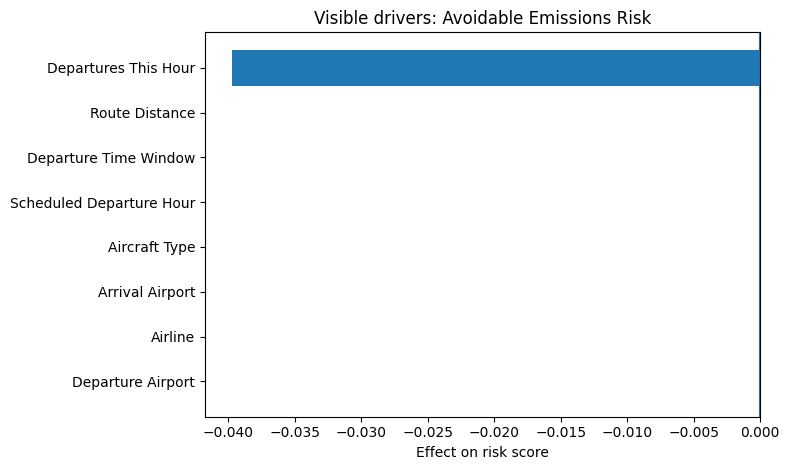

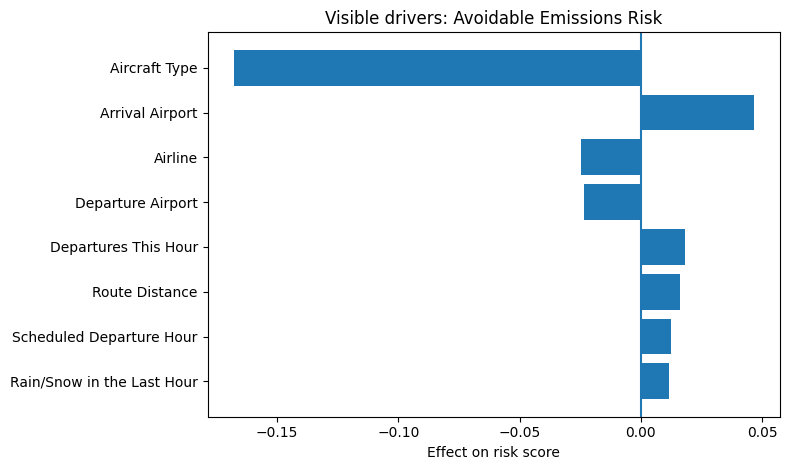

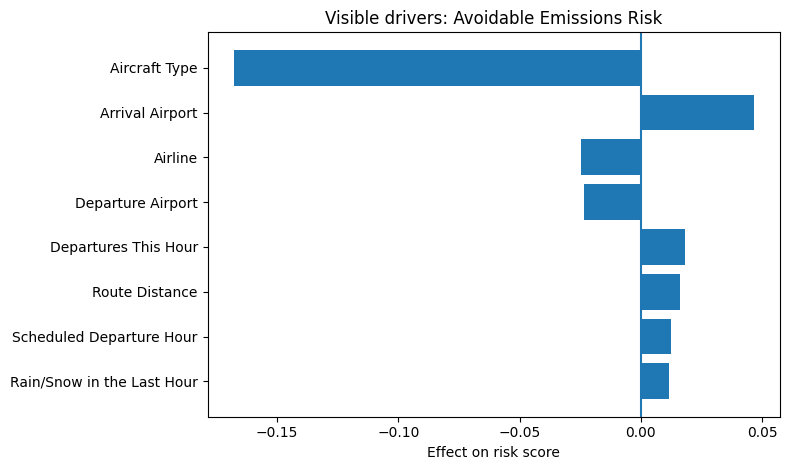

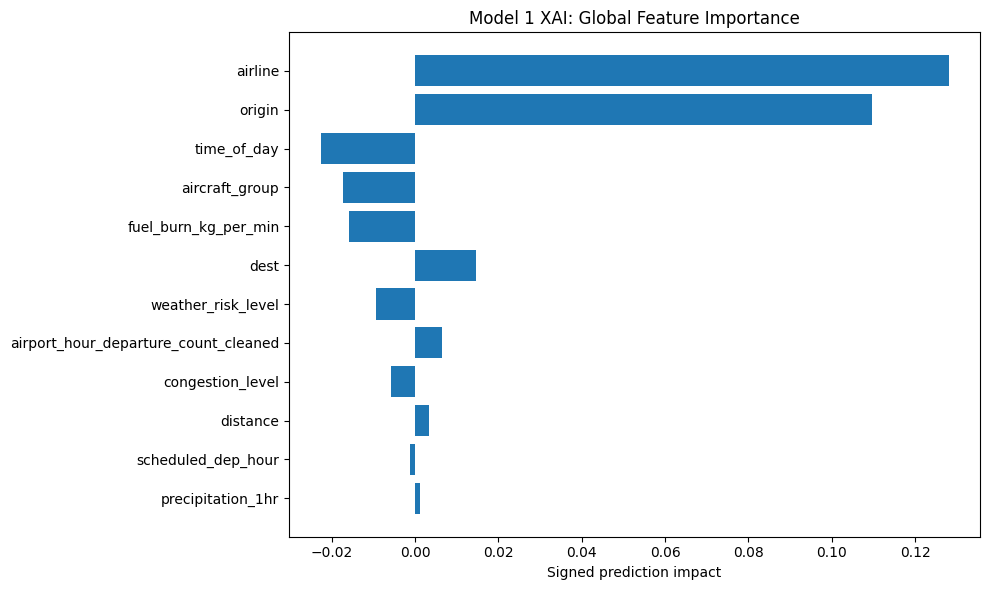

Model 1 local top features


model_name,explanation_type,feature,original_score,perturbed_score,signed_impact,absolute_impact,replacement_value,created_at
Model 1 - High Avoidable Emissions,local_high_prediction,airline,0.7615032271661746,0.38841558548417726,0.3730876416819973,0.3730876416819973,WN,2026-05-22T14:43:11.430511
Model 1 - High Avoidable Emissions,local_high_prediction,origin,0.7615032271661746,0.5111134530341536,0.250389774132021,0.250389774132021,DEN,2026-05-22T14:43:09.444784
Model 1 - High Avoidable Emissions,local_high_prediction,airport_hour_departure_count_cleaned,0.7615032271661746,0.6745693724909106,0.08693385467526393,0.08693385467526393,18.0,2026-05-22T14:43:22.711417
Model 1 - High Avoidable Emissions,local_high_prediction,dest,0.7615032271661746,0.7507751321838187,0.01072809498235583,0.01072809498235583,ATL,2026-05-22T14:43:10.429072
Model 1 - High Avoidable Emissions,local_high_prediction,distance,0.7615032271661746,0.756777399642639,0.004725827523535564,0.004725827523535564,746.0,2026-05-22T14:43:20.368580
Model 1 - High Avoidable Emissions,local_high_prediction,time_of_day,0.7615032271661746,0.76596305665655,-0.004459829490375378,0.004459829490375378,morning,2026-05-22T14:43:14.432468
Model 1 - High Avoidable Emissions,local_high_prediction,day_of_week,0.7615032271661746,0.7645802371573014,-0.003077009991126811,0.003077009991126811,4.0,2026-05-22T14:43:18.429494
Model 1 - High Avoidable Emissions,local_high_prediction,scheduled_dep_hour,0.7615032271661746,0.75883880972083,0.0026644174453446245,0.0026644174453446245,13.0,2026-05-22T14:43:19.373688
Model 1 - High Avoidable Emissions,local_high_prediction,weather_risk_level,0.7615032271661746,0.7615032271661746,0.0,0.0,unknown,2026-05-22T14:43:16.394502
Model 1 - High Avoidable Emissions,local_high_prediction,congestion_level,0.7615032271661746,0.7615032271661746,0.0,0.0,high,2026-05-22T14:43:15.428572


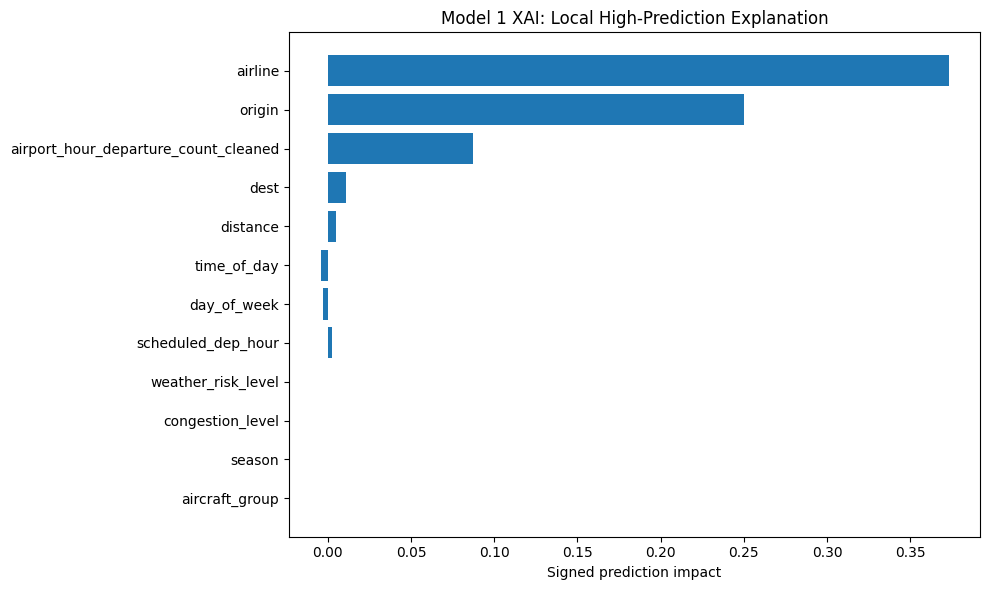

Model 2 global top features


model_name,explanation_type,feature,baseline_score,perturbed_score,signed_impact,absolute_impact,replacement_value,sample_rows,created_at
Model 2 - High Delay Risk,global,airline,0.24300634583999137,0.29138227787782345,-0.04837593203783208,0.04837593203783208,WN,300,2026-05-22T14:43:40.018471
Model 2 - High Delay Risk,global,origin,0.24300634583999137,0.2712321259086328,-0.02822578006864146,0.02822578006864146,DEN,300,2026-05-22T14:43:37.788915
Model 2 - High Delay Risk,global,time_of_day,0.24300634583999137,0.21982497919258862,0.02318136664740275,0.02318136664740275,morning,300,2026-05-22T14:43:43.982528
Model 2 - High Delay Risk,global,dest,0.24300634583999137,0.2529400183667493,-0.00993367252675792,0.00993367252675792,ATL,300,2026-05-22T14:43:38.894235
Model 2 - High Delay Risk,global,aircraft_group,0.24300634583999137,0.24938359692488282,-0.006377251084891455,0.006377251084891455,narrow_body,300,2026-05-22T14:43:41.024158
Model 2 - High Delay Risk,global,scheduled_dep_hour,0.24300634583999137,0.23827851177347423,0.004727834066517139,0.004727834066517139,13.0,300,2026-05-22T14:43:48.928517
Model 2 - High Delay Risk,global,congestion_level,0.24300634583999137,0.2473629824642334,-0.004356636624242044,0.004356636624242044,high,300,2026-05-22T14:43:44.922095
Model 2 - High Delay Risk,global,congestion_score,0.24300634583999137,0.24480948198576247,-0.0018031361457711004,0.0018031361457711004,2.0,300,2026-05-22T14:43:55.650904
Model 2 - High Delay Risk,global,fuel_burn_kg_per_min,0.24300634583999137,0.24152903947037316,0.0014773063696182087,0.0014773063696182087,12.0,300,2026-05-22T14:43:51.032001
Model 2 - High Delay Risk,global,precipitation_1hr,0.24300634583999137,0.24161656924370964,0.0013897765962817277,0.0013897765962817277,0.0,300,2026-05-22T14:43:54.644679


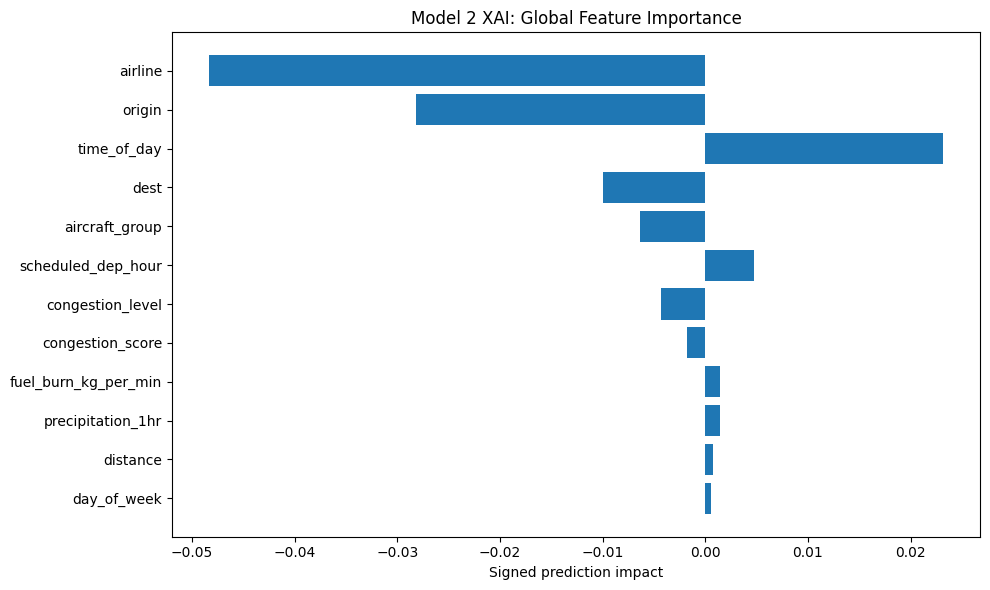

Model 2 local top features


model_name,explanation_type,feature,original_score,perturbed_score,signed_impact,absolute_impact,replacement_value,created_at
Model 2 - High Delay Risk,local_high_prediction,precipitation_1hr,0.5199947312361275,0.3504398056770284,0.16955492555909907,0.16955492555909907,0.0,2026-05-22T14:44:21.279733
Model 2 - High Delay Risk,local_high_prediction,scheduled_dep_hour,0.5199947312361275,0.4526176904597267,0.06737704077640078,0.06737704077640078,13.0,2026-05-22T14:44:16.275014
Model 2 - High Delay Risk,local_high_prediction,time_of_day,0.5199947312361275,0.46715542534071824,0.05283930589540925,0.05283930589540925,morning,2026-05-22T14:44:11.053339
Model 2 - High Delay Risk,local_high_prediction,origin,0.5199947312361275,0.5662711910343246,-0.046276459798197056,0.046276459798197056,DEN,2026-05-22T14:44:05.737507
Model 2 - High Delay Risk,local_high_prediction,dest,0.5199947312361275,0.5508807444222071,-0.03088601318607964,0.03088601318607964,ATL,2026-05-22T14:44:06.753096
Model 2 - High Delay Risk,local_high_prediction,airline,0.5199947312361275,0.5014311775594115,0.018563553676716027,0.018563553676716027,WN,2026-05-22T14:44:07.773380
Model 2 - High Delay Risk,local_high_prediction,day_of_week,0.5199947312361275,0.5312603153664234,-0.01126558413029588,0.01126558413029588,4.0,2026-05-22T14:44:15.314703
Model 2 - High Delay Risk,local_high_prediction,weather_risk_level,0.5199947312361275,0.5106779972880852,0.009316733948042333,0.009316733948042333,unknown,2026-05-22T14:44:13.355113
Model 2 - High Delay Risk,local_high_prediction,distance,0.5199947312361275,0.5145861036895519,0.005408627546575562,0.005408627546575562,746.0,2026-05-22T14:44:17.277756
Model 2 - High Delay Risk,local_high_prediction,wind_speed,0.5199947312361275,0.5219755515015898,-0.001980820265462313,0.001980820265462313,3.6,2026-05-22T14:44:20.258404


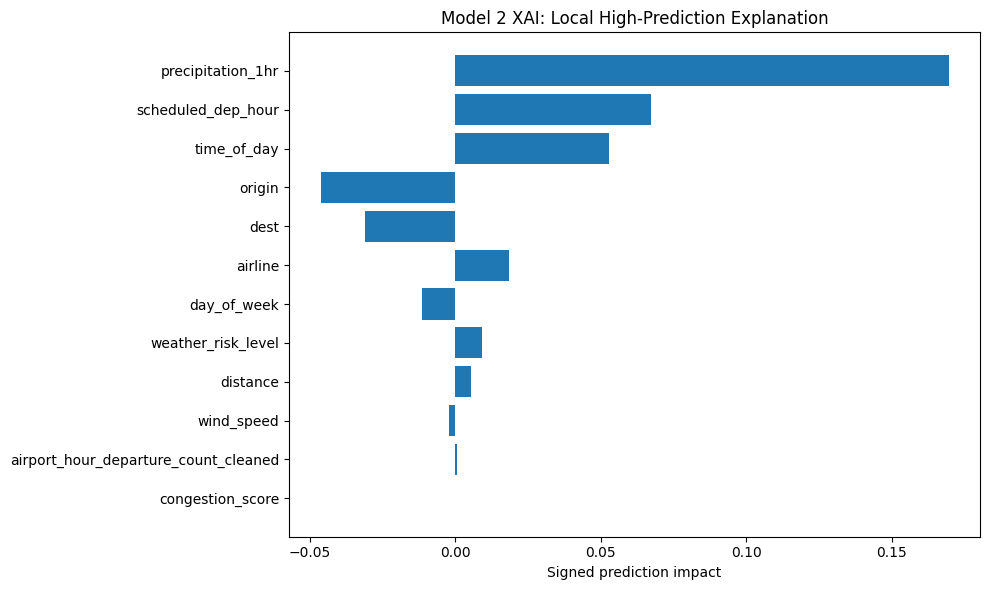

In [0]:
#XAI for Model 1 and Model 2
emission_feature_model = PipelineModel.load(PIPELINE_PATH)
emission_model = MultilayerPerceptronClassificationModel.load(BEST_MODEL_PATH)
delay_feature_model = PipelineModel.load(DELAY_PIPELINE_PATH)
delay_model_loaded = MultilayerPerceptronClassificationModel.load(DELAY_MODEL_PATH)

original_feature_cols_raw = feature_cols_raw
original_numeric_cols = numeric_cols

try:
    emission_feature_cols = [c for c in original_feature_cols_raw if c != "congestion_score"]
    emission_numeric_cols = [c for c in original_numeric_cols if c != "congestion_score"]

    feature_cols_raw = emission_feature_cols
    numeric_cols = emission_numeric_cols
    emission_raw_test = spark.table(MLP_SPLIT_TABLE).where(F.col("set") == "test").select(*feature_cols_raw).dropna()

    model1_global_xai = global_perturbation_importance("Model 1 - High Avoidable Emissions", emission_raw_test, emission_feature_model, emission_model)
    model1_local_xai = local_perturbation_explanation("Model 1 - High Avoidable Emissions", emission_raw_test, emission_feature_model, emission_model)

    feature_cols_raw = original_feature_cols_raw
    numeric_cols = original_numeric_cols
    delay_raw_test = spark.table(DELAY_SPLIT_TABLE).where(F.col("set") == "test").select(*feature_cols_raw).dropna()

    model2_global_xai = global_perturbation_importance("Model 2 - High Delay Risk", delay_raw_test, delay_feature_model, delay_model_loaded)
    model2_local_xai = local_perturbation_explanation("Model 2 - High Delay Risk", delay_raw_test, delay_feature_model, delay_model_loaded)
finally:
    feature_cols_raw = original_feature_cols_raw
    numeric_cols = original_numeric_cols

all_global = pd.concat([model1_global_xai, model2_global_xai], ignore_index=True)
all_local = pd.concat([model1_local_xai, model2_local_xai], ignore_index=True)
spark.createDataFrame(all_global).write.format("delta").mode("append").option("mergeSchema", "true").saveAsTable(XAI_GLOBAL_TABLE)
spark.createDataFrame(all_local).write.format("delta").mode("append").option("mergeSchema", "true").saveAsTable(XAI_LOCAL_TABLE)

print("Model 1 global top features"); display(model1_global_xai.head(10))
plot_xai_bar(model1_global_xai, "Model 1 XAI: Global Feature Importance", "/tmp/model1_xai_global.png")
print("Model 1 local top features"); display(model1_local_xai.head(10))
plot_xai_bar(model1_local_xai, "Model 1 XAI: Local High-Prediction Explanation", "/tmp/model1_xai_local.png")

print("Model 2 global top features"); display(model2_global_xai.head(10))
plot_xai_bar(model2_global_xai, "Model 2 XAI: Global Feature Importance", "/tmp/model2_xai_global.png")
print("Model 2 local top features"); display(model2_local_xai.head(10))
plot_xai_bar(model2_local_xai, "Model 2 XAI: Local High-Prediction Explanation", "/tmp/model2_xai_local.png")

In [0]:
# Dashboard metric estimators for emissions value and delay minutes

import re
from pyspark.sql import functions as F

metrics_df = spark.table(GOLD_TABLE)


def _pick_col(df, candidates, required=True, label="column"):
    existing = {c.lower(): c for c in df.columns}

    for c in candidates:
        if c.lower() in existing:
            return existing[c.lower()]

    if required:
        raise ValueError(f"Could not find {label}. Tried: {candidates}")

    return None


def _q(c):
    return "`" + c.replace("`", "``") + "`"


def _norm(value):
    if value is None:
        return "unknown"

    value = str(value).strip().lower()

    return value if value else "unknown"


def _airport_key(value):
    if value is None:
        return "unknown"

    value = str(value).strip()
    match = re.match(r"^([A-Za-z]{3})", value)

    return match.group(1).lower() if match else value.lower()


def _departures_bin(value):
    try:
        value = float(value)
    except Exception:
        return "unknown"

    if value < 50:
        return "low"
    elif value < 150:
        return "medium"
    elif value < 250:
        return "high"
    else:
        return "severe"


def _rain_bin(value):
    try:
        value = float(value)
    except Exception:
        return "unknown"

    if value <= 0:
        return "none"
    elif value < 2.5:
        return "light"
    elif value < 7.5:
        return "medium"
    else:
        return "heavy"


def _hour_key(value):
    try:
        value = float(value)
    except Exception:
        return "unknown"

    return str(int(round(value)))


def _clip_probability(value):
    try:
        value = float(value)
    except Exception:
        return 0.0

    return max(0.0, min(1.0, value))


ORIGIN_COL = _pick_col(
    metrics_df,
    ["departure_airport", "origin", "origin_airport", "dep_airport"],
    label="departure airport column"
)

DEST_COL = _pick_col(
    metrics_df,
    ["arrival_airport", "dest", "destination_airport", "arr_airport"],
    required=False,
    label="arrival airport column"
)

AIRLINE_COL = _pick_col(
    metrics_df,
    ["airline", "carrier", "airline_name", "carrier_code"],
    required=False,
    label="airline column"
)

AIRCRAFT_COL = _pick_col(
    metrics_df,
    ["aircraft_type", "aircraft_category", "aircraft", "aircraft_group"],
    label="aircraft type column"
)

WEATHER_COL = _pick_col(
    metrics_df,
    ["weather_risk_level", "weather_risk", "weather_level"],
    required=False,
    label="weather risk column"
)

CONGESTION_COL = _pick_col(
    metrics_df,
    ["congestion_level", "airport_congestion_level", "congestion"],
    required=False,
    label="congestion level column"
)

DEPARTURES_COL = _pick_col(
    metrics_df,
    [
        "departures_this_hour",
        "departure_count_hour",
        "hourly_departures",
        "airport_hour_departure_count_cleaned"
    ],
    required=False,
    label="departures this hour column"
)

SCHEDULED_HOUR_COL = _pick_col(
    metrics_df,
    ["scheduled_dep_hour", "departure_hour", "dep_hour"],
    required=False,
    label="scheduled departure hour column"
)

RAIN_COL = _pick_col(
    metrics_df,
    [
        "rain_snow_last_hour",
        "rain_snow_1h",
        "precipitation_last_hour",
        "precipitation_1h",
        "precipitation_1hr"
    ],
    required=False,
    label="rain/snow column"
)

EMISSIONS_COL = _pick_col(
    metrics_df,
    [
        "avoidable_ground_co2_kg",
        "avoidable_emissions_kg",
        "avoidable_co2_kg",
        "excess_ground_co2_kg",
        "excess_co2_kg",
        "label_avoidable_ground_co2_kg"
    ],
    label="avoidable emissions column"
)

DELAY_COL = _pick_col(
    metrics_df,
    [
        "dep_delay_winsorized",
        "departure_delay_minutes",
        "dep_delay_minutes",
        "dep_delay",
        "delay_minutes",
        "arrival_delay_minutes",
        "arr_delay"
    ],
    required=False,
    label="delay minutes column"
)


def _add_text_key(df, source_col, new_col, airport=False):
    if source_col is None:
        return df.withColumn(new_col, F.lit("unknown"))

    raw = F.lower(
        F.trim(
            F.coalesce(
                F.col(source_col).cast("string"),
                F.lit("unknown")
            )
        )
    )

    if airport:
        code = F.lower(F.regexp_extract(raw, r"^([a-z]{3})", 1))
        return df.withColumn(new_col, F.when(code != "", code).otherwise(raw))

    return df.withColumn(new_col, raw)


base_metrics = metrics_df

base_metrics = _add_text_key(base_metrics, ORIGIN_COL, "_origin_key", airport=True)
base_metrics = _add_text_key(base_metrics, DEST_COL, "_dest_key", airport=True)
base_metrics = _add_text_key(base_metrics, AIRLINE_COL, "_airline_key")
base_metrics = _add_text_key(base_metrics, AIRCRAFT_COL, "_aircraft_key")
base_metrics = _add_text_key(base_metrics, WEATHER_COL, "_weather_key")
base_metrics = _add_text_key(base_metrics, CONGESTION_COL, "_congestion_key")

if DEPARTURES_COL:
    dep_value = F.col(DEPARTURES_COL).cast("double")

    base_metrics = base_metrics.withColumn(
        "_departures_bin",
        F.when(dep_value.isNull(), "unknown")
         .when(dep_value < 50, "low")
         .when(dep_value < 150, "medium")
         .when(dep_value < 250, "high")
         .otherwise("severe")
    )
else:
    base_metrics = base_metrics.withColumn("_departures_bin", F.lit("unknown"))

if RAIN_COL:
    rain_value = F.col(RAIN_COL).cast("double")

    base_metrics = base_metrics.withColumn(
        "_rain_bin",
        F.when(rain_value.isNull(), "unknown")
         .when(rain_value <= 0, "none")
         .when(rain_value < 2.5, "light")
         .when(rain_value < 7.5, "medium")
         .otherwise("heavy")
    )
else:
    base_metrics = base_metrics.withColumn("_rain_bin", F.lit("unknown"))

if SCHEDULED_HOUR_COL:
    hour_value = F.col(SCHEDULED_HOUR_COL).cast("double")

    base_metrics = base_metrics.withColumn(
        "_dep_hour_key",
        F.when(hour_value.isNull(), "unknown")
         .otherwise(F.round(hour_value).cast("int").cast("string"))
    )
else:
    base_metrics = base_metrics.withColumn("_dep_hour_key", F.lit("unknown"))


# Avoidable emissions estimator
# estimated kg CO2 =
# historical median + risk_score * (historical p90 - historical median)

emission_metric_df = base_metrics.withColumn(
    "_avoidable_emissions_kg",
    F.greatest(F.col(EMISSIONS_COL).cast("double"), F.lit(0.0))
)

GLOBAL_EMISSIONS_MEDIAN = float(
    emission_metric_df.select(
        F.expr("percentile_approx(_avoidable_emissions_kg, 0.5)").alias("v")
    ).first()["v"] or 0.0
)

GLOBAL_EMISSIONS_P90 = float(
    emission_metric_df.select(
        F.expr("percentile_approx(_avoidable_emissions_kg, 0.9)").alias("v")
    ).first()["v"] or GLOBAL_EMISSIONS_MEDIAN
)

EMISSION_KEYS = [
    "_origin_key",
    "_aircraft_key",
    "_departures_bin",
    "_weather_key"
]

emission_stats = (
    emission_metric_df
    .groupBy(*EMISSION_KEYS)
    .agg(
        F.count("*").alias("_n"),
        F.expr("percentile_approx(_avoidable_emissions_kg, 0.5)").alias("_median"),
        F.expr("percentile_approx(_avoidable_emissions_kg, 0.9)").alias("_p90")
    )
    .where(F.col("_n") >= 10)
)

EMISSION_LOOKUP = {
    tuple(row[k] for k in EMISSION_KEYS): (
        float(row["_median"] or 0.0),
        float(row["_p90"] or row["_median"] or 0.0)
    )
    for row in emission_stats.collect()
}


def estimate_avoidable_emissions_kg(
    departure_airport,
    aircraft_type,
    departures_this_hour,
    weather_risk_level,
    risk_score
):
    p = _clip_probability(risk_score)

    key = (
        _airport_key(departure_airport),
        _norm(aircraft_type),
        _departures_bin(departures_this_hour),
        _norm(weather_risk_level)
    )

    median_value, p90_value = EMISSION_LOOKUP.get(
        key,
        (GLOBAL_EMISSIONS_MEDIAN, GLOBAL_EMISSIONS_P90)
    )

    p90_value = max(p90_value, median_value)
    estimated = median_value + p * (p90_value - median_value)

    return round(max(0.0, estimated), 2)


# Delay estimator
# estimated delay minutes =
# historical median delay + delay_risk_score * (historical p90 delay - historical median delay)


if DELAY_COL is not None:
    delay_metric_df = base_metrics.withColumn(
        "_delay_minutes",
        F.greatest(F.col(DELAY_COL).cast("double"), F.lit(0.0))
    )

    GLOBAL_DELAY_MEDIAN = float(
        delay_metric_df.select(
            F.expr("percentile_approx(_delay_minutes, 0.5)").alias("v")
        ).first()["v"] or 0.0
    )

    GLOBAL_DELAY_P90 = float(
        delay_metric_df.select(
            F.expr("percentile_approx(_delay_minutes, 0.9)").alias("v")
        ).first()["v"] or GLOBAL_DELAY_MEDIAN
    )

    GLOBAL_DELAY_P90 = max(GLOBAL_DELAY_P90, GLOBAL_DELAY_MEDIAN)

    def _build_delay_lookup(keys):
        stats = (
            delay_metric_df
            .groupBy(*keys)
            .agg(
                F.count("*").alias("_n"),
                F.expr("percentile_approx(_delay_minutes, 0.5)").alias("_median"),
                F.expr("percentile_approx(_delay_minutes, 0.9)").alias("_p90")
            )
            .where(F.col("_n") >= 10)
        )

        return {
            tuple(row[k] for k in keys): (
                float(row["_median"] or 0.0),
                float(row["_p90"] or row["_median"] or 0.0)
            )
            for row in stats.collect()
        }

    DELAY_KEYS_FULL = [
        "_origin_key",
        "_dest_key",
        "_airline_key",
        "_aircraft_key",
        "_congestion_key",
        "_departures_bin",
        "_weather_key",
        "_rain_bin",
        "_dep_hour_key"
    ]

    DELAY_KEYS_MEDIUM = [
        "_origin_key",
        "_aircraft_key",
        "_congestion_key",
        "_departures_bin",
        "_weather_key",
        "_rain_bin"
    ]

    DELAY_KEYS_SIMPLE = [
        "_origin_key",
        "_congestion_key",
        "_departures_bin",
        "_weather_key",
        "_rain_bin"
    ]

    DELAY_KEYS_HOUR = [
        "_airline_key",
        "_departures_bin",
        "_dep_hour_key"
    ]

    DELAY_LOOKUP_FULL = _build_delay_lookup(DELAY_KEYS_FULL)
    DELAY_LOOKUP_MEDIUM = _build_delay_lookup(DELAY_KEYS_MEDIUM)
    DELAY_LOOKUP_SIMPLE = _build_delay_lookup(DELAY_KEYS_SIMPLE)
    DELAY_LOOKUP_HOUR = _build_delay_lookup(DELAY_KEYS_HOUR)

else:
    GLOBAL_DELAY_MEDIAN = 0.0
    GLOBAL_DELAY_P90 = 0.0
    DELAY_LOOKUP_FULL = {}
    DELAY_LOOKUP_MEDIUM = {}
    DELAY_LOOKUP_SIMPLE = {}
    DELAY_LOOKUP_HOUR = {}

    print("Warning: no delay-minutes column was found. Add your delay column name to DELAY_COL candidates.")


def estimate_delay_minutes(
    departure_airport,
    arrival_airport,
    airline,
    aircraft_type,
    weather_risk_level,
    rain_snow_last_hour,
    risk_score,
    congestion_level=None,
    departures_this_hour=None,
    scheduled_dep_hour=None
):
    if DELAY_COL is None:
        return None

    p = _clip_probability(risk_score)

    congestion_key = _norm(congestion_level)
    departures_key = _departures_bin(departures_this_hour)
    hour_key = _hour_key(scheduled_dep_hour)

    full_key = (
        _airport_key(departure_airport),
        _airport_key(arrival_airport),
        _norm(airline),
        _norm(aircraft_type),
        congestion_key,
        departures_key,
        _norm(weather_risk_level),
        _rain_bin(rain_snow_last_hour),
        hour_key
    )

    medium_key = (
        _airport_key(departure_airport),
        _norm(aircraft_type),
        congestion_key,
        departures_key,
        _norm(weather_risk_level),
        _rain_bin(rain_snow_last_hour)
    )

    simple_key = (
        _airport_key(departure_airport),
        congestion_key,
        departures_key,
        _norm(weather_risk_level),
        _rain_bin(rain_snow_last_hour)
    )

    hour_lookup_key = (
        _norm(airline),
        departures_key,
        hour_key
    )

    values = (
        DELAY_LOOKUP_FULL.get(full_key)
        or DELAY_LOOKUP_MEDIUM.get(medium_key)
        or DELAY_LOOKUP_SIMPLE.get(simple_key)
        or DELAY_LOOKUP_HOUR.get(hour_lookup_key)
        or (GLOBAL_DELAY_MEDIAN, GLOBAL_DELAY_P90)
    )

    median_delay, p90_delay = values
    p90_delay = max(p90_delay, median_delay)

    estimated_delay = median_delay + p * (p90_delay - median_delay)

    return int(round(max(0.0, estimated_delay)))



In [0]:
# Data and helpers for the airport performance (RQ2) and reduction scenario (RQ3) tabs
import os
import sys
import importlib

notebook_path = dbutils.notebook.entry_point.getDbutils().notebook().getContext().notebookPath().get()
REPO_ROOT = "/Workspace" + os.path.dirname(os.path.dirname(notebook_path))
sys.path.insert(0, f"{REPO_ROOT}/src")
import rq3_scenarios as rq3
importlib.reload(rq3)

RQ2 = spark.table("`new`.`airgreenops`.`rq2_airport_ranking`").toPandas().sort_values("adjusted_co2_kg_per_movement")
RQ2_AIRPORTS = RQ2["airport"].tolist()
RQ2_DEFAULT = ["ATL", "JFK", "ORD", "DEN", "LAX"]

RQ3_DEP = spark.table("`new`.`airgreenops`.`rq3_components_departures`").toPandas()
RQ3_ARR = spark.table("`new`.`airgreenops`.`rq3_components_arrivals`").toPandas()
RQ3_TURN = spark.table("`new`.`airgreenops`.`rq3_components_turnarounds`").toPandas()


def rq2_chart(selected):
    selected = selected or []
    r = RQ2.reset_index(drop=True)
    colors = ["#d62728" if a in selected else "#9aa5b1" for a in r["airport"]]
    fig, ax = plt.subplots(figsize=(7, 11))
    for i, row in r.iterrows():
        ax.errorbar(row["adjusted_co2_kg_per_movement"], i,
                    xerr=[[row["adjusted_co2_kg_per_movement"] - row["adjusted_ci_low"]], [row["adjusted_ci_high"] - row["adjusted_co2_kg_per_movement"]]],
                    fmt="o", markersize=3, capsize=2, color=colors[i])
    ax.axvline(0, linestyle="--", color="black", linewidth=0.8)
    ax.set_yticks(range(len(r)))
    ax.set_yticklabels(r["airport"], fontsize=6)
    ax.invert_yaxis()
    ax.set_xlabel("Extra ground CO2 per movement vs network average (kg), comparable conditions")
    ax.set_title("Airport ground operations performance (taxi-out + taxi-in)")
    plt.tight_layout()
    return fig


def rq2_table(selected):
    r = RQ2[RQ2["airport"].isin(selected)] if selected else pd.concat([RQ2.head(5), RQ2.tail(5)])
    out = pd.DataFrame({
        "Airport": r["airport"],
        "Movements 2023-25": r["movements"].astype(int),
        "Adjusted kg CO2 / movement": r["adjusted_co2_kg_per_movement"].round(1),
        "Raw kg CO2 / movement": r["co2_kg_per_movement"].round(1),
        "Rank adjusted (1 = best)": r["rank_adjusted"].astype(int),
        "Rank raw": r["rank_raw"].astype(int),
        "Rank EM06DS green score": r["rank_em06ds"],
    })
    return out


def rq3_calculate(airport, hold_share, set_saving, warmup, cooldown, eligible_other, apu_share, apu_min, grid, level):
    p = rq3.pick(level)
    p.update({"hold_share": float(hold_share), "set_saving": float(set_saving), "warmup_min": int(warmup),
              "cooldown_min": int(cooldown), "set_eligible_other": float(eligible_other), "apu_share_of_turn": float(apu_share),
              "apu_min_with_gpu": int(apu_min), "grid_kg_per_kwh": float(grid)})
    res = rq3.scenario(RQ3_DEP, RQ3_ARR, RQ3_TURN, p)
    if airport != "All 76 airports":
        res = res.loc[[airport]]
    tot = res.sum(numeric_only=True)
    base = tot["baseline_ground_co2_kg"]
    measures = [("Gate hold", "s1_kg"), ("Gate hold, only when gates are free", "s1_offpeak_kg"),
                ("Single-engine taxi", "s2_kg"), ("Ground power at stand", "s3_kg"), ("Combined", "combined_kg")]
    table = pd.DataFrame({
        "Measure": [m for m, _ in measures],
        "Tonnes CO2 saved per year": [round(tot[c] / 1000, 0) for _, c in measures],
        "% of ground CO2 (taxi + APU)": [round(tot[c] / base * 100, 1) for _, c in measures],
    })
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.barh(table["Measure"], table["Tonnes CO2 saved per year"], color="#2ca02c")
    ax.invert_yaxis()
    ax.set_xlabel("Tonnes CO2 saved per year (2025 traffic)")
    ax.set_title(f"{airport}: baseline ground CO2 {base / 1e9:.2f} Mt" if airport == "All 76 airports" else f"{airport}: baseline ground CO2 {base / 1e6:.1f} kt")
    plt.tight_layout()
    return table, fig


# Consistency check: the dashboard must reproduce notebook 06 (central assumptions, all airports)
dash_total = rq3.scenario(RQ3_DEP, RQ3_ARR, RQ3_TURN, rq3.pick("central"))["combined_kg"].sum() / 1000
nb06_total = (spark.table("`new`.`airgreenops`.`rq3_national_savings`")
              .where("scenario = 'Combined 1 + 2 + 3'").select("central").first()[0])
print(f"Combined saving, central: dashboard {dash_total:,.0f} t | notebook 06 {nb06_total:,.0f} t")
if abs(dash_total - nb06_total) > 1:
    raise Exception("Dashboard scenario calculator does not match notebook 06")

Emissions tab visible inputs: ['Airline', 'Departure Airport', 'Departure Time Window', 'Departures This Hour', 'Aircraft Type', 'Arrival Airport', 'Weather Risk Level']
Delay tab visible inputs: ['Airline', 'Rain/Snow in the Last Hour', 'Departure Airport', 'Departure Time Window', 'Arrival Airport', 'Scheduled Departure Hour', 'Aircraft Type', 'Airport Congestion Level']
Congestion bridge active: {'low': 15.0, 'medium': 30.0, 'high': 45.0, 'severe': 60.0, 'unknown': 30.0}
Running on local URL:  http://127.0.0.1:7860
Running on public URL: https://f07bcb7e80150530a3.gradio.live

This share link expires in 72 hours. For free permanent hosting and GPU upgrades, run `gradio deploy` from Terminal to deploy to Spaces (https://huggingface.co/spaces)


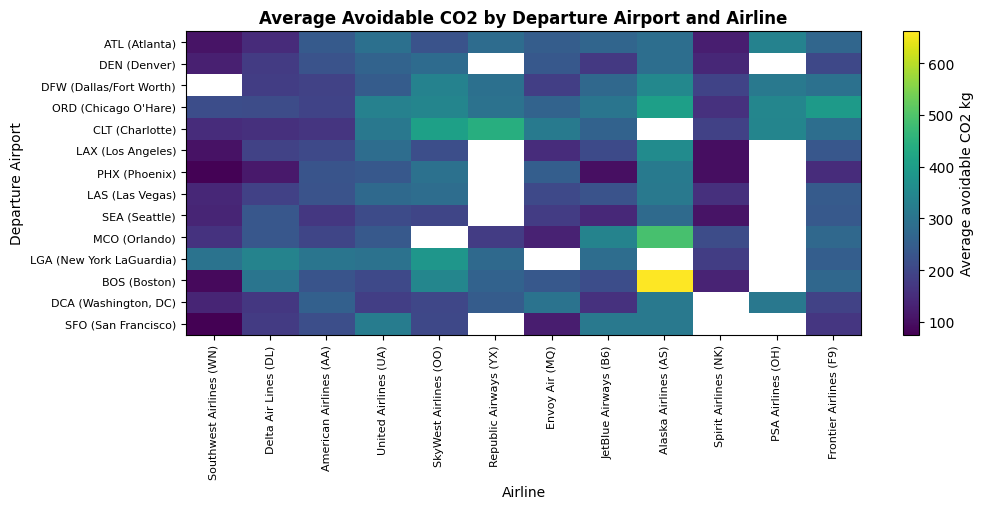

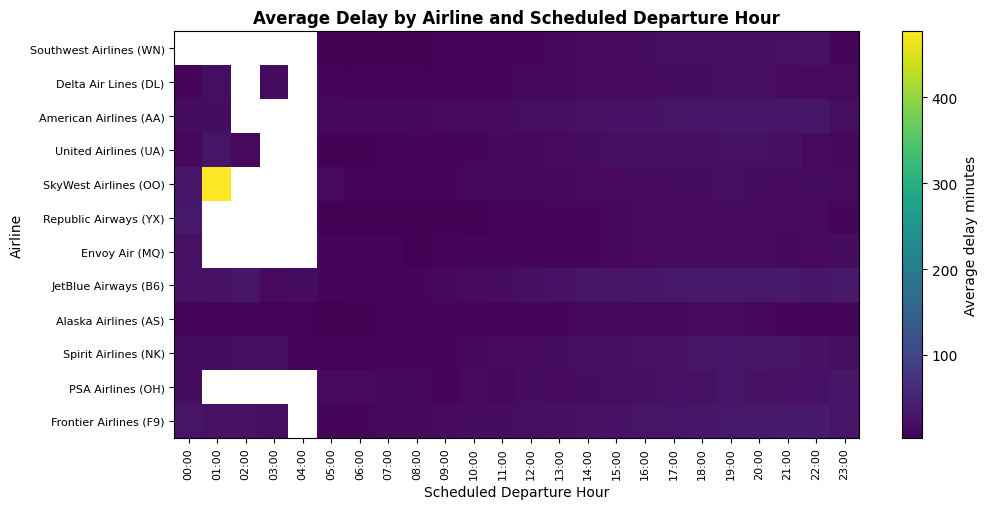

In [0]:
# Gradio dashboard

import html
import re
import traceback

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gradio as gr

from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType
from pyspark.ml import PipelineModel
from pyspark.ml.classification import MultilayerPerceptronClassificationModel
from pyspark.ml.linalg import VectorUDT

try:
    from pyspark.ml.functions import vector_to_array
except Exception:
    vector_to_array = None

# Load models

SEED = globals().get("SEED", 42)

if "BEST_MODEL_PATH" not in globals():
    best_row = (
        spark.table(MLP_RESULTS_TABLE)
        .orderBy(F.desc("validation_f1_high_emission"), F.desc("validation_auc"))
        .first()
    )
    BEST_MODEL_PATH = best_row["model_path"]

emission_feature_model = PipelineModel.load(PIPELINE_PATH)
emission_model = MultilayerPerceptronClassificationModel.load(BEST_MODEL_PATH)

delay_feature_model = PipelineModel.load(DELAY_PIPELINE_PATH)
delay_model_loaded = MultilayerPerceptronClassificationModel.load(DELAY_MODEL_PATH)


# Model input schema

DEFAULT_CAT = [
    "origin", "dest", "airline", "aircraft_group",
    "season", "time_of_day", "congestion_level", "weather_risk_level"
]

DEFAULT_NUM = [
    "month", "day_of_week", "scheduled_dep_hour", "distance",
    "fuel_burn_kg_per_min", "airport_hour_departure_count_cleaned",
    "wind_speed", "precipitation_1hr"
]

DEP_COUNT_COL = "airport_hour_departure_count_cleaned"


def pipeline_input_cols(pipe):
    cats, nums = [], []

    for stage in pipe.stages:
        try:
            out_col = stage.getOutputCol()
        except Exception:
            continue

        if out_col == "num_vec":
            try:
                nums = list(stage.getInputCols())
            except Exception:
                pass

        elif str(out_col).endswith("_idx"):
            try:
                cats.append(stage.getInputCol())
            except Exception:
                pass

    return cats, nums


cat1, num1 = pipeline_input_cols(emission_feature_model)
cat2, num2 = pipeline_input_cols(delay_feature_model)

gold0 = spark.table(GOLD_TABLE)
gold_cols = set(gold0.columns)

categorical_cols = list(dict.fromkeys(cat1 + cat2 + [c for c in DEFAULT_CAT if c in gold_cols]))
numeric_cols = list(dict.fromkeys(num1 + num2 + [c for c in DEFAULT_NUM if c in gold_cols]))


def congestion_score_expr(col_name="congestion_level"):
    c = F.lower(F.trim(F.coalesce(F.col(col_name).cast("string"), F.lit("unknown"))))

    return (
        F.when(c.isin("very low", "low", "light"), F.lit(0.0))
         .when(c.isin("medium", "moderate", "normal"), F.lit(1.0))
         .when(c.isin("high", "heavy"), F.lit(2.0))
         .when(c.isin("severe", "very high", "extreme"), F.lit(3.0))
         .otherwise(F.lit(1.0))
    )


gold_for_ui = gold0

if "congestion_level" in gold_cols and "congestion_score" not in numeric_cols:
    
    numeric_cols.append("congestion_score")

if "congestion_score" in numeric_cols and "congestion_score" not in gold_for_ui.columns:
    gold_for_ui = gold_for_ui.withColumn("congestion_score", congestion_score_expr("congestion_level"))

feature_cols_raw = list(dict.fromkeys(categorical_cols + numeric_cols))

missing = [c for c in feature_cols_raw if c not in gold_for_ui.columns]
if missing:
    raise ValueError(f"Dashboard missing required model columns: {missing}")


# Labels and display helpers

FEATURE_LABELS = {
    "origin": "Departure Airport",
    "dest": "Arrival Airport",
    "airline": "Airline",
    "aircraft_group": "Aircraft Type",
    "season": "Travel Season",
    "time_of_day": "Departure Time Window",
    "congestion_level": "Airport Congestion Level",
    "weather_risk_level": "Weather Risk Level",
    "month": "Travel Month",
    "day_of_week": "Day of Week",
    "scheduled_dep_hour": "Scheduled Departure Hour",
    "distance": "Route Distance",
    "fuel_burn_kg_per_min": "Estimated Fuel Consumption",
    DEP_COUNT_COL: "Departures This Hour",
    "congestion_score": "Congestion Severity Score",
    "wind_speed": "Wind Speed",
    "precipitation_1hr": "Rain/Snow in the Last Hour",
}

FEATURE_DESCRIPTIONS = {
    "origin": "Choose the departure airport.",
    "dest": "Choose the arrival airport.",
    "airline": "Choose the operating airline.",
    "aircraft_group": "Choose the aircraft type. Fuel consumption is estimated automatically from this selection.",
    "time_of_day": "Choose the departure time window.",
    "congestion_level": "Choose how busy the departure airport is around this flight time.",
    "weather_risk_level": "Choose the overall weather disruption risk around the flight.",
    "scheduled_dep_hour": "Planned departure hour using a 24-hour clock. Unit: hour.",
    DEP_COUNT_COL: "Number of departures scheduled from the airport in the same hour. Unit: departures.",
    "precipitation_1hr": "Rain or snow measured in the hour around departure. Unit: precipitation.",
}

AIRLINE_NAMES = {
    "AA": "American Airlines",
    "DL": "Delta Air Lines",
    "UA": "United Airlines",
    "WN": "Southwest Airlines",
    "B6": "JetBlue Airways",
    "AS": "Alaska Airlines",
    "NK": "Spirit Airlines",
    "F9": "Frontier Airlines",
    "HA": "Hawaiian Airlines",
    "G4": "Allegiant Air",
    "OO": "SkyWest Airlines",
    "YX": "Republic Airways",
    "MQ": "Envoy Air",
    "OH": "PSA Airlines",
    "9E": "Endeavor Air",
}

AIRPORT_NAMES = {
    "ATL": "Atlanta",
    "BOS": "Boston",
    "BWI": "Baltimore",
    "CLT": "Charlotte",
    "DCA": "Washington, DC",
    "DEN": "Denver",
    "DFW": "Dallas/Fort Worth",
    "DTW": "Detroit",
    "EWR": "Newark",
    "FLL": "Fort Lauderdale",
    "IAD": "Washington Dulles",
    "IAH": "Houston Intercontinental",
    "JFK": "New York",
    "LAS": "Las Vegas",
    "LAX": "Los Angeles",
    "LGA": "New York LaGuardia",
    "MCO": "Orlando",
    "MDW": "Chicago Midway",
    "MIA": "Miami",
    "MSP": "Minneapolis/St. Paul",
    "ORD": "Chicago O'Hare",
    "PDX": "Portland",
    "PHL": "Philadelphia",
    "PHX": "Phoenix",
    "SAN": "San Diego",
    "SEA": "Seattle",
    "SFO": "San Francisco",
    "SJC": "San Jose",
    "SLC": "Salt Lake City",
    "TPA": "Tampa",
    "AUS": "Austin",
    "BNA": "Nashville",
    "CLE": "Cleveland",
    "CMH": "Columbus",
    "CVG": "Cincinnati",
    "DAL": "Dallas Love Field",
    "HOU": "Houston Hobby",
    "IND": "Indianapolis",
    "JAX": "Jacksonville",
    "MCI": "Kansas City",
    "MKE": "Milwaukee",
    "MSY": "New Orleans",
    "OAK": "Oakland",
    "ONT": "Ontario",
    "PIT": "Pittsburgh",
    "RDU": "Raleigh/Durham",
    "SAT": "San Antonio",
    "SMF": "Sacramento",
    "SNA": "Orange County",
    "STL": "St. Louis",
    "SJU": "San Juan",
}


def manager_label(feature_name):
    return FEATURE_LABELS.get(feature_name, feature_name.replace("_", " ").title())


def _text(value):
    if value is None:
        return ""
    return str(value).strip()


def _norm_display_key(value):
    return re.sub(r"[^a-z0-9]+", " ", _text(value).lower()).strip()


def _safe_float(value, default=0.0):
    try:
        if value is None:
            return default
        v = float(value)
        return default if np.isnan(v) else v
    except Exception:
        return default


def _extract_airline_code(value):
    s = _text(value).upper()

    paren = re.search(r"\(([A-Z0-9]{2})\)", s)
    if paren:
        return paren.group(1)

    if re.fullmatch(r"[A-Z0-9]{2}", s):
        return s

    first_token = re.match(r"^([A-Z0-9]{2})\b", s)
    if first_token and first_token.group(1) in AIRLINE_NAMES:
        return first_token.group(1)

    return None


def _extract_airport_code(value):
    s = _text(value).upper()

    paren = re.search(r"\(([A-Z]{3})\)", s)
    if paren:
        return paren.group(1)

    first_token = re.match(r"^([A-Z]{3})\b", s)
    if first_token:
        return first_token.group(1)

    if re.fullmatch(r"[A-Z]{3}", s):
        return s

    return None


def clean_value(value):
    if value is None:
        return "Unknown"

    s = str(value).strip()
    if not s:
        return "Unknown"

    if re.fullmatch(r"[A-Za-z]{2,4}\d?", s):
        return s.upper()

    words = s.replace("_", " ").replace("-", " ").split()
    fixed = []

    for w in words:
        upper = w.upper()
        if upper in AIRLINE_NAMES or upper in AIRPORT_NAMES:
            fixed.append(upper)
        elif re.fullmatch(r"[A-Za-z]{2,4}\d?", w):
            fixed.append(upper)
        else:
            fixed.append(w.capitalize())

    return " ".join(fixed) if fixed else "Unknown"


def airline_display(value):
    s = _text(value)
    if not s:
        return "Unknown"

    code = _extract_airline_code(s)
    if code and code in AIRLINE_NAMES:
        return f"{AIRLINE_NAMES[code]} ({code})"

    return clean_value(s)


def airport_display(value):
    s = _text(value)
    if not s:
        return "Unknown"

    code = _extract_airport_code(s)
    if code:
        city = AIRPORT_NAMES.get(code)
        return f"{code} ({city})" if city else code

    return clean_value(s)


def aircraft_display(value):
    s = _text(value)
    if not s:
        return "Unknown"

    k = _norm_display_key(s)

    if "wide" in k and "body" in k:
        return "Wide-body aircraft"
    if "narrow" in k and "body" in k:
        return "Narrow-body aircraft"
    if "regional" in k and "jet" in k:
        return "Regional jet"
    if "regional" in k:
        return "Regional aircraft"
    if "turboprop" in k or "turbo prop" in k:
        return "Turboprop aircraft"
    if "jet" in k:
        return "Jet aircraft"

    return clean_value(s)


def risk_level_display(value):
    s = _text(value)
    if not s:
        return "Unknown"

    k = _norm_display_key(s)
    mapping = {
        "very low": "Very Low",
        "low": "Low",
        "light": "Low",
        "medium": "Medium",
        "moderate": "Medium",
        "normal": "Medium",
        "high": "High",
        "heavy": "High",
        "severe": "Severe",
        "very high": "Severe",
        "extreme": "Severe",
    }

    return mapping.get(k, clean_value(s))


def time_window_display(value):
    s = _text(value)
    if not s:
        return "Unknown"

    k = _norm_display_key(s)
    mapping = {
        "early morning": "Early Morning",
        "morning": "Morning",
        "midday": "Midday",
        "afternoon": "Afternoon",
        "evening": "Evening",
        "night": "Night",
        "overnight": "Overnight",
    }

    return mapping.get(k, clean_value(s))


def display_value(feature_name, value):
    if feature_name == "scheduled_dep_hour":
        return f"{int(round(_safe_float(value))):02d}:00"

    if feature_name == "distance":
        return f"{_safe_float(value):,.0f} miles"

    if feature_name == "fuel_burn_kg_per_min":
        return f"{_safe_float(value):,.1f} kg/min"

    if feature_name == DEP_COUNT_COL:
        return f"{_safe_float(value):,.0f} departures"

    if feature_name == "precipitation_1hr":
        return f"{_safe_float(value):,.2f}"

    if feature_name == "wind_speed":
        return f"{_safe_float(value):,.1f}"

    if feature_name in numeric_cols:
        return f"{_safe_float(value):,.2f}"

    if feature_name in ["origin", "dest"]:
        return airport_display(value)

    if feature_name == "airline":
        return airline_display(value)

    if feature_name == "aircraft_group":
        return aircraft_display(value)

    if feature_name in ["congestion_level", "weather_risk_level"]:
        return risk_level_display(value)

    if feature_name == "time_of_day":
        return time_window_display(value)

    return clean_value(value)


# Defaults

raw_defaults = (
    gold_for_ui
    .select(*feature_cols_raw)
    .dropna()
    .limit(30000)
    .cache()
)

if raw_defaults.count() == 0:
    raw_defaults.unpersist()
    raw_defaults = (
        gold_for_ui
        .select(*feature_cols_raw)
        .limit(30000)
        .cache()
    )


def categorical_default(df, col):
    row = (
        df.where(F.col(col).isNotNull())
        .groupBy(col)
        .count()
        .orderBy(F.desc("count"))
        .first()
    )

    return row[col] if row else "unknown"


def numeric_default(df, col):
    vals = df.where(F.col(col).isNotNull()).approxQuantile(col, [0.5], 0.01)
    return float(vals[0]) if vals else 0.0


ui_defaults = {c: categorical_default(raw_defaults, c) for c in categorical_cols}
ui_defaults.update({c: numeric_default(raw_defaults, c) for c in numeric_cols})



MODEL1_UI_FEATURES = [
    "airline",
    "origin",
    "time_of_day",
    DEP_COUNT_COL,
    "aircraft_group",
    "dest",
    "weather_risk_level",
]

MODEL2_UI_FEATURES = [
    "airline",
    "precipitation_1hr",
    "origin",
    "time_of_day",
    "dest",
    "scheduled_dep_hour",
    "aircraft_group",
    "congestion_level",
]

MODEL1_UI_FEATURES = [f for f in MODEL1_UI_FEATURES if f in feature_cols_raw and f != "fuel_burn_kg_per_min"]
MODEL2_UI_FEATURES = [f for f in MODEL2_UI_FEATURES if f in feature_cols_raw and f != "fuel_burn_kg_per_min" and f != DEP_COUNT_COL]

print("Emissions tab visible inputs:", [manager_label(f) for f in MODEL1_UI_FEATURES])
print("Delay tab visible inputs:", [manager_label(f) for f in MODEL2_UI_FEATURES])


CONGESTION_TO_DEPARTURE_COUNT = {
    "low": 15.0,
    "medium": 30.0,
    "high": 45.0,
    "severe": 60.0,
    "unknown": 30.0,
}


def _congestion_key(value):
    s = _norm_display_key(value)

    if s in ["very low", "low", "light"]:
        return "low"

    if s in ["medium", "moderate", "normal"]:
        return "medium"

    if s in ["high", "heavy"]:
        return "high"

    if s in ["severe", "very high", "extreme"]:
        return "severe"

    return "unknown" if not s else s


def _congestion_score(value):
    return {"low": 0.0, "medium": 1.0, "high": 2.0, "severe": 3.0}.get(_congestion_key(value), 1.0)


def _departure_count_for_congestion(congestion_level):
    return float(
        CONGESTION_TO_DEPARTURE_COUNT.get(
            _congestion_key(congestion_level),
            CONGESTION_TO_DEPARTURE_COUNT["medium"]
        )
    )


def _departures_bin(value):
    try:
        v = float(value)
    except Exception:
        return "unknown"

    if v < 20:
        return "low"
    if v < 40:
        return "medium"
    if v < 55:
        return "high"
    return "severe"


def apply_congestion_bridge(row, force=True):
    level = row.get("congestion_level", ui_defaults.get("congestion_level", "medium"))

    if "congestion_score" in numeric_cols:
        row["congestion_score"] = float(_congestion_score(level))

    if force and DEP_COUNT_COL in numeric_cols:
        row[DEP_COUNT_COL] = float(_departure_count_for_congestion(level))

    return row


print("Congestion bridge active:", CONGESTION_TO_DEPARTURE_COUNT)


# Dropdown choices and sliders

visible_features = list(dict.fromkeys(MODEL1_UI_FEATURES + MODEL2_UI_FEATURES))
visible_categorical = [c for c in visible_features if c in categorical_cols]
visible_numeric = [c for c in visible_features if c in numeric_cols]

ui_choices = {}
CHOICE_LABEL_TO_RAW = {}
RAW_TO_CHOICE_LABEL = {}


def _choice_matches(feature_name, raw_value, desired_value):
    raw_norm = _norm_display_key(raw_value)
    desired_norm = _norm_display_key(desired_value)
    display_norm = _norm_display_key(display_value(feature_name, raw_value))

    if raw_norm == desired_norm or display_norm == desired_norm:
        return True

    if feature_name in ["origin", "dest"]:
        raw_code = _extract_airport_code(raw_value)
        desired_code = _extract_airport_code(desired_value)
        return raw_code is not None and desired_code is not None and raw_code == desired_code

    if feature_name == "airline":
        raw_code = _extract_airline_code(raw_value)
        desired_code = _extract_airline_code(desired_value)
        return raw_code is not None and desired_code is not None and raw_code == desired_code

    if feature_name == "aircraft_group":
        return _norm_display_key(aircraft_display(raw_value)) == _norm_display_key(aircraft_display(desired_value))

    if feature_name in ["congestion_level", "weather_risk_level"]:
        return _norm_display_key(risk_level_display(raw_value)) == _norm_display_key(risk_level_display(desired_value))

    if feature_name == "time_of_day":
        return _norm_display_key(time_window_display(raw_value)) == _norm_display_key(time_window_display(desired_value))

    return False


def _unique_label(feature_name, raw_value, used_labels):
    base_label = display_value(feature_name, raw_value)
    label = base_label

    if label in used_labels:
        raw_suffix = clean_value(raw_value)
        label = f"{base_label} [{raw_suffix}]"

    used_labels.add(label)
    return label


def _build_dropdown_choices(feature_name):
    rows = (
        raw_defaults
        .where(F.col(feature_name).isNotNull())
        .groupBy(feature_name)
        .count()
        .orderBy(F.desc("count"))
        .limit(120)
        .collect()
    )

    values = [r[feature_name] for r in rows if r[feature_name] is not None]

    default_raw = ui_defaults.get(feature_name)
    ordered_values = []

    if default_raw is not None:
        ordered_values.append(default_raw)

    for raw_value in values:
        if str(raw_value) != str(default_raw):
            ordered_values.append(raw_value)

    choices = []
    label_to_raw = {}
    raw_to_label = {}
    used = set()

    for raw_value in ordered_values:
        label = _unique_label(feature_name, raw_value, used)
        choices.append(label)                 # string label shown in the dropdown
        label_to_raw[str(label)] = raw_value  # raw value sent to Spark model
        raw_to_label[str(raw_value)] = label

    return choices, label_to_raw, raw_to_label


for c in visible_categorical:
    choices, label_to_raw, raw_to_label = _build_dropdown_choices(c)
    ui_choices[c] = choices
    CHOICE_LABEL_TO_RAW[c] = label_to_raw
    RAW_TO_CHOICE_LABEL[c] = raw_to_label


def default_choice_label(feature_name):
    raw_value = ui_defaults.get(feature_name)
    return RAW_TO_CHOICE_LABEL.get(feature_name, {}).get(str(raw_value), display_value(feature_name, raw_value))


def coerce_categorical_value(feature_name, selected_value):
    """Convert manager-friendly dropdown label back to the raw model value."""
    if selected_value is None:
        return ui_defaults.get(feature_name)

    selected_text = str(selected_value)

    mapped = CHOICE_LABEL_TO_RAW.get(feature_name, {}).get(selected_text)
    if mapped is not None:
        return mapped

    for raw_value in CHOICE_LABEL_TO_RAW.get(feature_name, {}).values():
        if str(raw_value).strip().lower() == selected_text.strip().lower():
            return raw_value

    if feature_name == "airline":
        selected_code = _extract_airline_code(selected_text)
        for raw_value in CHOICE_LABEL_TO_RAW.get(feature_name, {}).values():
            if selected_code and _extract_airline_code(raw_value) == selected_code:
                return raw_value

    if feature_name in ["origin", "dest"]:
        selected_code = _extract_airport_code(selected_text)
        for raw_value in CHOICE_LABEL_TO_RAW.get(feature_name, {}).values():
            if selected_code and _extract_airport_code(raw_value) == selected_code:
                return raw_value

    if feature_name == "aircraft_group":
        wanted = _norm_display_key(aircraft_display(selected_text))
        for raw_value in CHOICE_LABEL_TO_RAW.get(feature_name, {}).values():
            if _norm_display_key(aircraft_display(raw_value)) == wanted:
                return raw_value

    if feature_name in ["congestion_level", "weather_risk_level"]:
        wanted = _norm_display_key(risk_level_display(selected_text))
        for raw_value in CHOICE_LABEL_TO_RAW.get(feature_name, {}).values():
            if _norm_display_key(risk_level_display(raw_value)) == wanted:
                return raw_value

    if feature_name == "time_of_day":
        wanted = _norm_display_key(time_window_display(selected_text))
        for raw_value in CHOICE_LABEL_TO_RAW.get(feature_name, {}).values():
            if _norm_display_key(time_window_display(raw_value)) == wanted:
                return raw_value

    return selected_value


numeric_bounds = {}

for c in visible_numeric:
    qs = raw_defaults.where(F.col(c).isNotNull()).approxQuantile(c, [0.05, 0.50, 0.95], 0.01)

    if len(qs) == 3:
        low, med, high = [float(x) for x in qs]
    else:
        low = med = float(ui_defaults.get(c, 0.0))
        high = low + 1.0

    if c == "scheduled_dep_hour":
        low, high = 0.0, 23.0

    if c in [DEP_COUNT_COL, "precipitation_1hr"]:
        low = max(0.0, low)

    default = float(ui_defaults.get(c, med))

    numeric_bounds[c] = {
        "minimum": min(low, default),
        "maximum": max(high, default + 1.0),
        "value": default,
    }


def slider_step(feature_name):
    if feature_name in ["month", "day_of_week", "scheduled_dep_hour", DEP_COUNT_COL]:
        return 1

    if feature_name == "precipitation_1hr":
        return 0.01

    return 0.1


# Automated fuel card

AUTO_FUEL_BY_AIRCRAFT_GROUP = {}

if "aircraft_group" in feature_cols_raw and "fuel_burn_kg_per_min" in feature_cols_raw:
    fuel_rows = (
        raw_defaults
        .where(F.col("aircraft_group").isNotNull() & F.col("fuel_burn_kg_per_min").isNotNull())
        .groupBy("aircraft_group")
        .agg(F.expr("percentile_approx(fuel_burn_kg_per_min, 0.5)").alias("fuel"))
        .collect()
    )

    AUTO_FUEL_BY_AIRCRAFT_GROUP = {
        str(r["aircraft_group"]): float(r["fuel"])
        for r in fuel_rows
        if r["aircraft_group"] is not None and r["fuel"] is not None
    }

DEFAULT_FUEL_BURN = float(ui_defaults.get("fuel_burn_kg_per_min", 0.0))


def get_auto_fuel(aircraft_group):
    raw = coerce_categorical_value("aircraft_group", aircraft_group)
    key = str(raw)

    if key in AUTO_FUEL_BY_AIRCRAFT_GROUP:
        return AUTO_FUEL_BY_AIRCRAFT_GROUP[key]

    for raw_key, value in AUTO_FUEL_BY_AIRCRAFT_GROUP.items():
        if str(raw_key).lower() == key.lower():
            return float(value)

    return DEFAULT_FUEL_BURN


def fuel_info_html(aircraft_group):
    raw = coerce_categorical_value("aircraft_group", aircraft_group)
    fuel = get_auto_fuel(raw)

    return f"""
    <div class="info-box">
        <div class="info-title">Automated fuel consumption</div>
        <div class="info-value">{fuel:,.1f} kg/min</div>
        <div class="info-note">
            Estimated automatically from the selected aircraft type:
            <b>{html.escape(display_value("aircraft_group", raw))}</b>. This value is sent to the model.
        </div>
    </div>
    """

# Metric estimators

def first_existing(candidates):
    cols_lower = {c.lower(): c for c in gold_for_ui.columns}

    for c in candidates:
        if c in gold_for_ui.columns:
            return c

        if c.lower() in cols_lower:
            return cols_lower[c.lower()]

    return None


EMISSION_COL = first_existing([
    "avoidable_ground_co2_kg", "avoidable_emissions_kg", "avoidable_co2_kg",
    "excess_ground_co2_kg", "excess_co2_kg", "label_avoidable_ground_co2_kg"
])

DELAY_COL = first_existing([
    "dep_delay_winsorized", "departure_delay_minutes", "dep_delay_minutes",
    "dep_delay", "delay_minutes", "arrival_delay_minutes", "arr_delay"
])


def _norm_key(value):
    s = str(value).strip().lower() if value is not None else "unknown"
    return s if s else "unknown"


def _precip_bin(value):
    v = _safe_float(value, None)

    if v is None:
        return "unknown"

    if v <= 0:
        return "none"

    if v < 2.5:
        return "light"

    if v < 7.5:
        return "medium"

    return "heavy"


def _hour_key(value):
    return str(int(round(_safe_float(value, 0.0))))


metric_cols = list(dict.fromkeys(feature_cols_raw + [c for c in [EMISSION_COL, DELAY_COL] if c is not None]))

metric_pdf = (
    gold_for_ui
    .select(*metric_cols)
    .sample(False, 0.03, seed=SEED)
    .limit(50000)
    .toPandas()
)

if metric_pdf.empty:
    metric_pdf = gold_for_ui.select(*metric_cols).limit(50000).toPandas()


def add_metric_keys(pdf):
    work = pdf.copy()

    for c in ["origin", "dest", "airline", "aircraft_group", "weather_risk_level", "congestion_level"]:
        work[f"{c}_k"] = work[c].apply(_norm_key) if c in work.columns else "unknown"

    work["dep_bin"] = work[DEP_COUNT_COL].apply(_departures_bin) if DEP_COUNT_COL in work.columns else "unknown"
    work["precip_bin"] = work["precipitation_1hr"].apply(_precip_bin) if "precipitation_1hr" in work.columns else "unknown"
    work["hour_k"] = work["scheduled_dep_hour"].apply(_hour_key) if "scheduled_dep_hour" in work.columns else "unknown"

    return work


metric_pdf = add_metric_keys(metric_pdf)


def metric_is_binary(pdf, col):
    if col is None or col not in pdf.columns:
        return True

    vals = pd.to_numeric(pdf[col], errors="coerce").dropna().unique()
    return len(vals) <= 2 and set(vals).issubset({0, 1, 0.0, 1.0})


def build_estimator(metric_col, key_sets, min_count=5):
    if metric_col is None or metric_col not in metric_pdf.columns:
        return {"ready": False, "global": (0.0, 0.0), "lookups": []}

    work = metric_pdf.copy()
    work["_metric"] = pd.to_numeric(work[metric_col], errors="coerce")
    work = work.dropna(subset=["_metric"])
    work["_metric"] = work["_metric"].clip(lower=0)

    if work.empty:
        return {"ready": False, "global": (0.0, 0.0), "lookups": []}

    global_median = float(work["_metric"].median())
    global_p90 = float(work["_metric"].quantile(0.90))
    global_p90 = max(global_p90, global_median)

    lookups = []

    for keys in key_sets:
        grouped = (
            work
            .groupby(keys, dropna=False)["_metric"]
            .agg(n="count", median="median", p90=lambda x: x.quantile(0.90))
            .reset_index()
        )

        grouped = grouped[grouped["n"] >= min_count]

        lookup = {}

        for _, r in grouped.iterrows():
            lookup[tuple(str(r[k]) for k in keys)] = (
                float(r["median"]),
                max(float(r["p90"]), float(r["median"]))
            )

        lookups.append((keys, lookup))

    return {"ready": True, "global": (global_median, global_p90), "lookups": lookups}


DELAY_KEY_SETS = [
    ["origin_k", "dest_k", "airline_k", "aircraft_group_k", "congestion_level_k", "dep_bin", "weather_risk_level_k", "precip_bin", "hour_k"],
    ["origin_k", "congestion_level_k", "dep_bin", "weather_risk_level_k", "precip_bin"],
    ["congestion_level_k", "dep_bin", "weather_risk_level_k"],
    ["airline_k", "hour_k"],
]

EMISSION_KEY_SETS = [
    ["origin_k", "aircraft_group_k", "dep_bin", "weather_risk_level_k"],
    ["aircraft_group_k", "weather_risk_level_k"],
    ["aircraft_group_k"],
]

DELAY_ESTIMATOR = build_estimator(DELAY_COL, DELAY_KEY_SETS)
EMISSION_ESTIMATOR = build_estimator(None if metric_is_binary(metric_pdf, EMISSION_COL) else EMISSION_COL, EMISSION_KEY_SETS)


def row_context(row):
    return {
        "origin_k": _norm_key(row.get("origin")),
        "dest_k": _norm_key(row.get("dest")),
        "airline_k": _norm_key(row.get("airline")),
        "aircraft_group_k": _norm_key(row.get("aircraft_group")),
        "weather_risk_level_k": _norm_key(row.get("weather_risk_level")),
        "congestion_level_k": _norm_key(row.get("congestion_level")),
        "dep_bin": _departures_bin(row.get(DEP_COUNT_COL)),
        "precip_bin": _precip_bin(row.get("precipitation_1hr")),
        "hour_k": _hour_key(row.get("scheduled_dep_hour")),
    }


def estimate_metric(row, score, estimator):
    if not estimator.get("ready"):
        return None

    ctx = row_context(row)

    for keys, lookup in estimator["lookups"]:
        key = tuple(ctx[k] for k in keys)
        if key in lookup:
            med, p90 = lookup[key]
            return med + float(score) * (p90 - med)

    med, p90 = estimator["global"]
    return med + float(score) * (p90 - med)


def estimate_delay(row, score):
    value = estimate_metric(row, score, DELAY_ESTIMATOR)
    return None if value is None else int(round(max(0.0, value)))


def estimate_emissions(row, score):
    value = estimate_metric(row, score, EMISSION_ESTIMATOR)
    return None if value is None else round(max(0.0, value), 1)


# ============================================================
# Heatmaps
# ============================================================

def _collect_grouped_average(rows_col, cols_col, value_col, top_rows=14, top_cols=12, hour_cols=False):
    if value_col is None:
        return pd.DataFrame()

    needed = [rows_col, cols_col, value_col]
    if any(c not in gold_for_ui.columns for c in needed):
        return pd.DataFrame()

    grouped = (
        gold_for_ui
        .where(F.col(rows_col).isNotNull() & F.col(cols_col).isNotNull() & F.col(value_col).isNotNull())
        .groupBy(rows_col, cols_col)
        .agg(
            F.avg(F.greatest(F.col(value_col).cast("double"), F.lit(0.0))).alias("avg_value"),
            F.count("*").alias("n")
        )
        .where(F.col("n") >= 3)
        .toPandas()
    )

    if grouped.empty:
        return grouped

    if hour_cols:
        grouped[cols_col] = pd.to_numeric(grouped[cols_col], errors="coerce").round().astype("Int64")
        grouped = grouped.dropna(subset=[cols_col])
        col_values = list(range(24))
    else:
        top_col_values = (
            grouped.groupby(cols_col)["n"]
            .sum()
            .sort_values(ascending=False)
            .head(top_cols)
            .index
            .tolist()
        )
        col_values = top_col_values

    row_values = (
        grouped.groupby(rows_col)["n"]
        .sum()
        .sort_values(ascending=False)
        .head(top_rows)
        .index
        .tolist()
    )

    filtered = grouped[grouped[rows_col].isin(row_values) & grouped[cols_col].isin(col_values)]

    pivot = filtered.pivot_table(
        index=rows_col,
        columns=cols_col,
        values="avg_value",
        aggfunc="mean"
    )

    pivot = pivot.reindex(index=row_values, columns=col_values)
    return pivot


def _heatmap_placeholder(title, message):
    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.text(0.5, 0.5, message, ha="center", va="center")
    ax.set_title(title)
    ax.set_axis_off()
    plt.tight_layout()
    return fig


def build_emissions_heatmap():
    pivot = _collect_grouped_average("origin", "airline", EMISSION_COL, top_rows=14, top_cols=12, hour_cols=False)

    if pivot.empty:
        return _heatmap_placeholder("Average Avoidable CO2 by Departure Airport and Airline", "No emissions heatmap data available")

    display_index = [airport_display(x) for x in pivot.index]
    display_cols = [airline_display(x) for x in pivot.columns]

    data = pivot.astype(float).values
    masked = np.ma.masked_invalid(data)

    fig, ax = plt.subplots(figsize=(10.5, 5.2))
    im = ax.imshow(masked, aspect="auto")
    ax.set_title("Average Avoidable CO2 by Departure Airport and Airline", fontweight="bold")
    ax.set_xlabel("Airline")
    ax.set_ylabel("Departure Airport")
    ax.set_xticks(np.arange(len(display_cols)))
    ax.set_xticklabels(display_cols, rotation=90, fontsize=8)
    ax.set_yticks(np.arange(len(display_index)))
    ax.set_yticklabels(display_index, fontsize=8)
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Average avoidable CO2 kg")
    plt.tight_layout()
    return fig


def build_delay_heatmap():
    pivot = _collect_grouped_average("airline", "scheduled_dep_hour", DELAY_COL, top_rows=12, top_cols=24, hour_cols=True)

    if pivot.empty:
        return _heatmap_placeholder("Average Delay by Airline and Scheduled Departure Hour", "No delay heatmap data available")

    display_index = [airline_display(x) for x in pivot.index]
    display_cols = [f"{int(x):02d}:00" for x in pivot.columns]

    data = pivot.astype(float).values
    masked = np.ma.masked_invalid(data)

    fig, ax = plt.subplots(figsize=(10.5, 5.2))
    im = ax.imshow(masked, aspect="auto")
    ax.set_title("Average Delay by Airline and Scheduled Departure Hour", fontweight="bold")
    ax.set_xlabel("Scheduled Departure Hour")
    ax.set_ylabel("Airline")
    ax.set_xticks(np.arange(len(display_cols)))
    ax.set_xticklabels(display_cols, rotation=90, fontsize=8)
    ax.set_yticks(np.arange(len(display_index)))
    ax.set_yticklabels(display_index, fontsize=8)
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Average delay minutes")
    plt.tight_layout()
    return fig


EMISSIONS_HEATMAP_FIG = build_emissions_heatmap()
DELAY_HEATMAP_FIG = build_delay_heatmap()


# ============================================================
# Scoring and explainability
# ============================================================

def vector_second(v):
    try:
        return float(v[1])
    except Exception:
        return None


_VECTOR_SECOND_UDF = F.udf(vector_second, DoubleType())


def score_sdf(raw_sdf, feature_model, classifier_model):
    pred = classifier_model.transform(feature_model.transform(raw_sdf))

    if "probability" in pred.columns:
        if isinstance(pred.schema["probability"].dataType, VectorUDT):
            if vector_to_array is not None:
                pred = pred.withColumn("p_positive", vector_to_array("probability").getItem(1).cast("double"))
            else:
                pred = pred.withColumn("p_positive", _VECTOR_SECOND_UDF("probability"))
        else:
            pred = pred.withColumn("p_positive", F.col("probability").cast("double"))
    else:
        pred = pred.withColumn("p_positive", F.col("prediction").cast("double"))

    return pred


def finalize_row(row):
    for c in categorical_cols:
        row[c] = str(row.get(c, "unknown"))

    for c in numeric_cols:
        row[c] = float(_safe_float(row.get(c, 0.0), 0.0))

    return row


def build_row(values, features, is_delay_model=False):
    row = dict(ui_defaults)

    for f, v in zip(features, values):
        if f in categorical_cols:
            row[f] = coerce_categorical_value(f, v)
        else:
            row[f] = float(v)

    if str(row.get("origin")).upper() == str(row.get("dest")).upper():
        raise gr.Error("Departure Airport and Arrival Airport cannot be the same.")

    if "fuel_burn_kg_per_min" in numeric_cols:
        row["fuel_burn_kg_per_min"] = float(get_auto_fuel(row.get("aircraft_group")))

    if is_delay_model and "congestion_level" in features:
        row = apply_congestion_bridge(row, force=True)

    return finalize_row(row)


def score_row(row, feature_model, classifier_model):
    sdf = spark.createDataFrame([row]).select(*feature_cols_raw)
    out = score_sdf(sdf, feature_model, classifier_model).select("prediction", "p_positive").first()

    return int(out["prediction"]), float(out["p_positive"])


def raw_choice_matching(feature_name, desired_value):
    desired = str(desired_value).strip().lower()

    for raw in CHOICE_LABEL_TO_RAW.get(feature_name, {}).values():
        if str(raw).strip().lower() == desired:
            return raw

        if feature_name in ["congestion_level", "weather_risk_level"]:
            if _norm_display_key(risk_level_display(raw)) == _norm_display_key(risk_level_display(desired_value)):
                return raw

        if feature_name == "aircraft_group":
            if _norm_display_key(aircraft_display(raw)) == _norm_display_key(aircraft_display(desired_value)):
                return raw

        if feature_name in ["origin", "dest"]:
            if _extract_airport_code(raw) and _extract_airport_code(raw) == _extract_airport_code(desired_value):
                return raw

        if feature_name == "airline":
            if _extract_airline_code(raw) and _extract_airline_code(raw) == _extract_airline_code(desired_value):
                return raw

    return desired_value


XAI_BASELINES = dict(ui_defaults)
XAI_BASELINES["congestion_level"] = raw_choice_matching("congestion_level", "medium")
XAI_BASELINES[DEP_COUNT_COL] = _departure_count_for_congestion("medium")

if "congestion_score" in numeric_cols:
    XAI_BASELINES["congestion_score"] = 1.0


def perturb_row(row, feature_name, baseline_value, is_delay_model=False):
    new_row = dict(row)
    new_row[feature_name] = baseline_value

    if feature_name == "aircraft_group" and "fuel_burn_kg_per_min" in numeric_cols:
        new_row["fuel_burn_kg_per_min"] = get_auto_fuel(baseline_value)

    if is_delay_model and feature_name == "congestion_level":
        new_row = apply_congestion_bridge(new_row, force=True)

    return finalize_row(new_row)


def risk_tier(score):
    if score >= 0.67:
        return "High Priority", "High Risk", "Intervene before departure.", "risk-high"

    if score >= 0.40:
        return "Medium Priority", "Medium Risk", "Monitor and prepare a contingency.", "risk-medium"

    return "Low Priority", "Low Risk", "Continue standard operations.", "risk-low"


def explanation_plot(xai_pdf, title):
    fig, ax = plt.subplots(figsize=(8, 4.8))

    if xai_pdf.empty:
        ax.text(0.5, 0.5, "No explanation available", ha="center", va="center")
        ax.set_axis_off()
        return fig

    p = xai_pdf.sort_values("absolute_impact", ascending=True)
    ax.barh([manager_label(x) for x in p["feature"]], p["signed_impact"])
    ax.axvline(0)
    ax.set_title(f"Visible drivers: {title}")
    ax.set_xlabel("Effect on risk score")
    plt.tight_layout()

    return fig


def result_card(model_label, score, xai_pdf, metric_label, metric_value, metric_unit, caption):
    priority, decision, action, css_class = risk_tier(score)

    if score >= 0.67:
        action_detail = "This flight should be reviewed before departure."
    elif score >= 0.40:
        action_detail = "This flight is not the highest priority, but it should stay visible to operations managers."
    else:
        action_detail = "No urgent intervention is suggested from the current model score."

    drivers = ""

    for r in xai_pdf.head(5).itertuples():
        direction = "raises risk" if r.signed_impact >= 0 else "reduces risk"
        drivers += (
            f"<li><b>{html.escape(manager_label(r.feature))}</b> "
            f"({html.escape(str(r.feature_value))}) {direction} by "
            f"<b>{abs(float(r.signed_impact)) * 100:.1f}%</b></li>"
        )

    return f"""
    <div class="result-card {css_class}">
        <div class="topline"><span class="pill">{priority}</span><b>{html.escape(model_label)}</b></div>
        <div class="score-row">
            <div><div class="score-label">Model decision</div><div class="score-value">{decision}</div></div>
            <div><div class="score-label">Risk score</div><div class="score-value">{score * 100:.1f}%</div></div>
            <div><div class="score-label">{html.escape(metric_label)}</div><div class="score-value">{metric_value} <span>{metric_unit}</span></div><div class="caption">{html.escape(caption)}</div></div>
        </div>
        <div class="action"><b>Recommended action:</b> {html.escape(action)}<br>{html.escape(action_detail)}</div>
        <div class="driver-box"><b>Top visible decision drivers</b><ul>{drivers}</ul></div>
        <div class="note">Fuel consumption is estimated automatically from aircraft type. Other hidden model fields are filled with median or mode baseline values.</div>
    </div>
    """


def explain(values, features, feature_model, classifier_model, model_label, is_delay_model=False):
    row = build_row(values, features, is_delay_model=is_delay_model)
    prediction, score = score_row(row, feature_model, classifier_model)

    rows = []

    for f, v in zip(features, values):
        shown_value = display_value(f, coerce_categorical_value(f, v) if f in categorical_cols else v)

        baseline = XAI_BASELINES.get(f, ui_defaults.get(f))
        base_row = perturb_row(row, f, baseline, is_delay_model=is_delay_model)
        _, base_score = score_row(base_row, feature_model, classifier_model)

        rows.append({
            "feature": f,
            "feature_value": shown_value,
            "signed_impact": score - base_score,
            "absolute_impact": abs(score - base_score),
        })

    xai_pdf = pd.DataFrame(rows).sort_values("absolute_impact", ascending=False).head(8)

    if is_delay_model:
        delay_minutes = estimate_delay(row, score)
        metric_value = "N/A" if delay_minutes is None else f"{delay_minutes:,}"
        metric_unit = "" if delay_minutes is None else "minutes"
        metric_label = "Estimated time delay"
        caption = "Potential delay"
    else:
        emissions_kg = estimate_emissions(row, score)
        metric_value = "N/A" if emissions_kg is None else f"{emissions_kg:,.0f}"
        metric_unit = "" if emissions_kg is None else "kg CO₂"
        metric_label = "Avoidable emissions"
        caption = "Estimated from historical CO₂ distribution"

    return (
        result_card(model_label, score, xai_pdf, metric_label, metric_value, metric_unit, caption),
        explanation_plot(xai_pdf, model_label)
    )


def predict_emissions(*values):
    return explain(
        values,
        MODEL1_UI_FEATURES,
        emission_feature_model,
        emission_model,
        "Avoidable Emissions Risk",
        is_delay_model=False
    )


def predict_delay(*values):
    return explain(
        values,
        MODEL2_UI_FEATURES,
        delay_feature_model,
        delay_model_loaded,
        "Delay Driven Operational Risk",
        is_delay_model=True
    )


def safe_predict(fn, label):
    def wrapper(*values):
        try:
            return fn(*values)
        except Exception as err:
            traceback.print_exc()
            fig, ax = plt.subplots(figsize=(8, 4.8))
            ax.text(0.5, 0.5, str(err), ha="center", va="center")
            ax.set_axis_off()
            return f"<div class='result-card risk-high'><b>{label} failed:</b><br>{html.escape(str(err))}</div>", fig

    return wrapper


# ============================================================
# Gradio components
# ============================================================

def make_inputs(features):
    inputs = []

    for f in features:
        if f in categorical_cols:
            inputs.append(
                gr.Dropdown(
                    choices=ui_choices.get(f, [default_choice_label(f)]),
                    value=default_choice_label(f),
                    label=manager_label(f),
                    info=FEATURE_DESCRIPTIONS.get(f, ""),
                    interactive=True,
                )
            )
        else:
            b = numeric_bounds[f]
            inputs.append(
                gr.Slider(
                    minimum=b["minimum"],
                    maximum=b["maximum"],
                    value=b["value"],
                    step=slider_step(f),
                    label=manager_label(f),
                    info=FEATURE_DESCRIPTIONS.get(f, ""),
                    interactive=True,
                )
            )

    return inputs


APP_CSS = """
.gradio-container {
    max-width: 1200px !important;
    font-family: Inter, Arial, sans-serif !important;
    background:#020617 !important;
    color:#e5e7eb !important;
}
body, .dark, .app {background:#020617 !important;}
.hero {
    padding:24px;
    border-radius:22px;
    background:linear-gradient(135deg,#0f766e,#1e3a8a);
    color:white;
    margin-bottom:18px;
}
.hero * {color:white !important; opacity:1 !important;}
.block, .form, .panel, .gradio-container .wrap {
    border-color:#1f2937 !important;
}
label, .prose, .markdown, .markdown p, .markdown li, .markdown strong {
    color:#e5e7eb !important;
}
input, textarea, select, .dropdown, .wrap, .container, .secondary-wrap {
    color:#e5e7eb !important;
}
button.primary, button[variant="primary"] {
    background:#f97316 !important;
    border-color:#f97316 !important;
    color:white !important;
    font-weight:800 !important;
}
.result-card {
    background:white !important;
    color:#0f172a !important;
    border:1px solid #cbd5e1;
    border-radius:18px;
    padding:16px;
    box-shadow:0 8px 20px rgba(15,23,42,.08);
    opacity:1 !important;
}
.result-card * {color:#0f172a !important; opacity:1 !important;}
.risk-high {border-left:8px solid #dc2626;}
.risk-medium {border-left:8px solid #f59e0b;}
.risk-low {border-left:8px solid #16a34a;}
.topline {display:flex; justify-content:space-between; gap:12px; margin-bottom:14px;}
.pill {background:#e2e8f0; border-radius:999px; padding:6px 10px; font-weight:900;}
.score-row {display:grid; grid-template-columns:repeat(auto-fit,minmax(150px,1fr)); gap:14px; margin-bottom:12px;}
.score-label {font-size:12px; font-weight:900; text-transform:uppercase; color:#475569 !important;}
.score-value {font-size:30px; font-weight:900; color:#0f172a !important;}
.score-value span {font-size:14px;}
.caption {font-size:12px; font-weight:700; color:#475569 !important;}
.action {background:#ecfdf5 !important; border:1px solid #86efac; border-radius:12px; padding:10px; margin-bottom:12px; color:#064e3b !important;}
.action * {color:#064e3b !important; opacity:1 !important;}
.driver-box {background:#f8fafc !important; border:1px solid #cbd5e1; border-radius:12px; padding:10px; color:#0f172a !important;}
.driver-box * {color:#0f172a !important; opacity:1 !important;}
.note {margin-top:10px; background:#eff6ff !important; border:1px solid #bfdbfe; border-radius:10px; padding:10px; font-size:13px; font-weight:700; color:#1e3a8a !important;}
.note * {color:#1e3a8a !important; opacity:1 !important;}
.info-box {
    background:#fff7ed !important;
    border:1px solid #fdba74 !important;
    border-radius:14px;
    padding:12px;
    margin:10px 0;
    color:#111827 !important;
    opacity:1 !important;
    filter:none !important;
}
.info-box * {color:#111827 !important; opacity:1 !important; filter:none !important;}
.info-title {color:#9a3412 !important; font-size:12px; font-weight:900; text-transform:uppercase; letter-spacing:.04em;}
.info-value {color:#111827 !important; font-size:26px; line-height:1.15; font-weight:900; margin-top:4px; margin-bottom:4px;}
.info-note {color:#1f2937 !important; font-size:13px; font-weight:700; line-height:1.35;}
.heatmap-title {font-weight:800; color:#e5e7eb; margin-top:18px; margin-bottom:8px;}
"""


# ============================================================
# Launch app
# ============================================================

with gr.Blocks(title="AirGreenOps Executive Decision Dashboard", css=APP_CSS) as demo:
    gr.HTML("""
    <div class="hero">
        <div style="font-size:12px; letter-spacing:.12em; text-transform:uppercase;">AirGreenOps decision intelligence</div>
        <div style="font-size:34px; font-weight:900;">Executive Flight Risk Dashboard</div>
        <div>A manager-friendly interface for identifying flights that may create avoidable emissions, operational disruption, and delay-driven cost.</div>
    </div>
    """)

    with gr.Tab("Sustainability Risk: Avoidable Emissions"):
        gr.Markdown("Use this tab to identify flights that may create **high avoidable emissions**. Recommended for sustainability planning, fuel efficiency review, and airport airline intervention decisions.")

        with gr.Row():
            with gr.Column():
                gr.Markdown("**Manager inputs**")
                inputs1 = make_inputs(MODEL1_UI_FEATURES)

                fuel_box1 = None
                if "aircraft_group" in MODEL1_UI_FEATURES:
                    fuel_box1 = gr.HTML(fuel_info_html(default_choice_label("aircraft_group")))

                btn1 = gr.Button("Assess emissions risk", variant="primary")

            with gr.Column():
                gr.Markdown("**Decision output**")
                out1 = gr.HTML()
                plot1 = gr.Plot(label="Visible decision drivers")

        if fuel_box1 is not None:
            ac1 = inputs1[MODEL1_UI_FEATURES.index("aircraft_group")]
            ac1.change(fuel_info_html, inputs=ac1, outputs=fuel_box1)

        btn1.click(safe_predict(predict_emissions, "Emissions model"), inputs=inputs1, outputs=[out1, plot1])

        gr.Markdown("**Executive heatmap**")
        gr.Plot(value=EMISSIONS_HEATMAP_FIG, label="High-density emissions dashboard")

    with gr.Tab("Operational Risk: Delay Exposure"):
        gr.Markdown("Use this tab to identify flights with **high delay-driven operational risk**. Recommended for schedule recovery, gate and crew planning, congestion control, and passenger experience protection.")

        with gr.Row():
            with gr.Column():
                gr.Markdown("**Manager inputs**")
                inputs2 = make_inputs(MODEL2_UI_FEATURES)

                fuel_box2 = None
                if "aircraft_group" in MODEL2_UI_FEATURES:
                    fuel_box2 = gr.HTML(fuel_info_html(default_choice_label("aircraft_group")))

                btn2 = gr.Button("Assess delay risk", variant="primary")

            with gr.Column():
                gr.Markdown("**Decision output**")
                out2 = gr.HTML()
                plot2 = gr.Plot(label="Visible decision drivers")

        if fuel_box2 is not None:
            ac2 = inputs2[MODEL2_UI_FEATURES.index("aircraft_group")]
            ac2.change(fuel_info_html, inputs=ac2, outputs=fuel_box2)

        btn2.click(safe_predict(predict_delay, "Delay model"), inputs=inputs2, outputs=[out2, plot2])

        gr.Markdown("**Executive heatmap**")
        gr.Plot(value=DELAY_HEATMAP_FIG, label="High-density delay-risk dashboard")

    with gr.Tab("Airport Performance: Comparable Conditions"):
        gr.Markdown("Extra ground CO2 per aircraft movement compared with the network average, holding airline, aircraft type, "
                    "time of day, season and traffic constant (RQ2, notebook 05). Negative = better than average. "
                    "Intervals use conventional standard errors and are likely too narrow; the ranking is stable across 2023-2025.")
        rq2_pick = gr.Dropdown(choices=RQ2_AIRPORTS, value=RQ2_DEFAULT, multiselect=True, label="Highlight airports")
        rq2_plot = gr.Plot(value=rq2_chart(RQ2_DEFAULT))
        rq2_df = gr.Dataframe(value=rq2_table(RQ2_DEFAULT), interactive=False)
        rq2_pick.change(lambda s: (rq2_chart(s), rq2_table(s)), inputs=rq2_pick, outputs=[rq2_plot, rq2_df])

    with gr.Tab("Reduction Scenarios: No Extra Delay"):
        gr.Markdown("Estimated CO2 saved per year (2025 traffic) by measures that keep take-off times, runway capacity and "
                    "turnaround times unchanged (RQ3, notebook 06). Fuel flow per taxi minute comes from the ICAO engine databank; "
                    "the inputs below are assumptions. Results are technical potential, not forecasts.")
        with gr.Row():
            sc_airport = gr.Dropdown(choices=["All 76 airports"] + RQ2_AIRPORTS, value="All 76 airports", label="Airport")
            sc_hold = gr.Radio([0.25, 0.5, 0.75], value=0.5, label="Gate hold: share of queue time moved to the gate")
            sc_set = gr.Slider(0.30, 0.50, value=0.40, step=0.05, label="Single-engine taxi: fuel saved per eligible minute")
        with gr.Row():
            sc_warm = gr.Radio([2, 3, 5], value=3, label="Engine warm-up before take-off (min)")
            sc_cool = gr.Radio([2, 3, 5], value=3, label="Engine cool-down after landing (min)")
            sc_elig = gr.Slider(0.70, 0.95, value=0.85, step=0.05, label="Share of flights eligible where no weather data")
        with gr.Row():
            sc_apu = gr.Radio([0.3, 0.5, 0.8], value=0.5, label="APU running share of turnaround today")
            sc_apu_min = gr.Radio([5, 10, 15], value=10, label="APU minutes still needed with ground power")
            sc_grid = gr.Slider(0.25, 0.45, value=0.37, step=0.01, label="Grid CO2 (kg per kWh)")
            sc_level = gr.Radio(["low", "central", "high"], value="central", label="APU fuel flow and ground power demand")
        sc_btn = gr.Button("Calculate savings")
        sc_table = gr.Dataframe(interactive=False)
        sc_plot = gr.Plot()
        sc_inputs = [sc_airport, sc_hold, sc_set, sc_warm, sc_cool, sc_elig, sc_apu, sc_apu_min, sc_grid, sc_level]
        sc_btn.click(rq3_calculate, inputs=sc_inputs, outputs=[sc_table, sc_plot])
        demo.load(rq3_calculate, inputs=sc_inputs, outputs=[sc_table, sc_plot])


raw_defaults.unpersist()

demo.launch(share=True, debug=False)
